# TravelTide — Exploratory Data Analysis

Explore the selected users’ behavior and assess data quality as a basis
for customer segmentation and reward recommendations.

Das Verhalten der ausgewählten Nutzer untersuchen und die Datenqualität
als Grundlage für Kundengruppen und Reward-Empfehlungen prüfen.

## 1. Packages / Pakete

Import packages for data analysis, visualization and later clustering.
Display the Python environment used by this notebook.

Pakete für Datenanalyse, Visualisierung und späteres Clustering importieren.
Die verwendete Python-Umgebung anzeigen.

In [1]:
# packages for data analysis, visualization and later clustering
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import airportsdata

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import HTML, display

print("Python environment:", sys.executable)

Python environment: c:\Users\mpero\Desktop\GitHub\TravelTide\.venv\Scripts\python.exe


## 2. Load and validate data / Daten laden und prüfen

### 2.1 Load sessions / Sessions laden

Determine the project folder and load the local session export.
Check the number of sessions and distinct users.

Den Projektordner bestimmen und den lokalen Session-Export laden.
Die Anzahl der Sessions und unterschiedlichen Nutzer prüfen.

In [2]:
# locate the project folder from either the root or notebooks directory
# projektordner vom hauptordner oder notebook-ordner aus bestimmen
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# load the local session export
# lokalen session-export laden
sessions = pd.read_csv(project_root / "data" / "raw" / "sessions.csv")

print("Sessions:", len(sessions))
print("Users / Nutzer:", sessions["user_id"].nunique())

Sessions: 49211
Users / Nutzer: 5998


In [60]:
# make project modules available from the notebook directory
project_path = str(project_root.resolve())

if project_path not in sys.path:
    sys.path.insert(0, project_path)

# import shared styling and raw-data overview
from src.plotting_style import (
    COLORS,
    PALETTE,
    GENDER_COLORS,
    style_overview,
    apply_plot_style,
)
from src.eda_functions import raw_data_overview

apply_plot_style()

### 2.2 Load remaining tables and validate exports
### Weitere Tabellen laden und Exporte prüfen

Load user, flight and hotel data. Compare all four table sizes with
the SQL results and check primary keys for missing and duplicate values.

Nutzer-, Flug- und Hoteldaten laden. Die Größe aller vier Tabellen mit
den SQL-Ergebnissen vergleichen und Primärschlüssel auf fehlende
und doppelte Werte prüfen.

In [4]:
# load the remaining local exports
# weitere lokale exportdateien laden
users = pd.read_csv(project_root / "data" / "raw" / "users.csv")
flights = pd.read_csv(project_root / "data" / "raw" / "flights.csv")
hotels = pd.read_csv(project_root / "data" / "raw" / "hotels.csv")

# compare exported row counts with SQL results and check primary keys
# exportierte zeilenzahlen mit SQL-ergebnissen vergleichen und schlüssel prüfen
tables = {
    "users": (users, "user_id", 5998),
    "sessions": (sessions, "session_id", 49211),
    "flights": (flights, "trip_id", 13717),
    "hotels": (hotels, "trip_id", 14313),
}

export_checks = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "expected_rows": expected,
        "row_count_matches": len(df) == expected,
        "missing_keys": df[key].isna().sum(),
        "duplicate_keys": df[key].duplicated().sum(),
    }
    for name, (df, key, expected) in tables.items()
])

# highlight validation results while keeping the shared table design
# prüfergebnisse hervorheben und gemeinsame tabellengestaltung verwenden
def highlight_check(value, expected):
    passed = value == expected
    background = "#DDEFEA" if passed else "#F5DFE3"
    color = "#24594D" if passed else "#8B3045"

    return (
        f"background-color: {background}; "
        f"color: {color}; font-weight: 600;"
    )


styled_checks = (
    style_overview(
        export_checks,
        "Export validation",
        {
            "rows": "{:,.0f}",
            "expected_rows": "{:,.0f}",
            "row_count_matches": (
                lambda value: "✓ OK" if value else "✗ Mismatch"
            ),
            "missing_keys": "{:,.0f}",
            "duplicate_keys": "{:,.0f}",
        },
    )
    .map(
        lambda value: highlight_check(value, True),
        subset=["row_count_matches"],
    )
    .map(
        lambda value: highlight_check(value, 0),
        subset=["missing_keys", "duplicate_keys"],
    )
)

display(styled_checks)

table,rows,expected_rows,row_count_matches,missing_keys,duplicate_keys
users,"5,998","5,998",✓ OK,0,0
sessions,"49,211","49,211",✓ OK,0,0
flights,"13,717","13,717",✓ OK,0,0
hotels,"14,313","14,313",✓ OK,0,0


### Findings / Erkenntnisse

All four exported row counts match the SQL results.
The primary keys contain no missing or duplicate values.

Alle vier exportierten Zeilenzahlen stimmen mit den SQL-Ergebnissen überein.
Die Primärschlüssel enthalten keine fehlenden oder doppelten Werte.

In [5]:
# create working copies and preserve the imported source data
# arbeitskopien erstellen und eingelesene ausgangsdaten erhalten
users_work = users.copy()
sessions_work = sessions.copy()
flights_work = flights.copy()
hotels_work = hotels.copy()

working_tables = {
    "users": users_work,
    "sessions": sessions_work,
    "flights": flights_work,
    "hotels": hotels_work,
}

## 3. Data types and missing values
## Datentypen und fehlende Werte

Inspect the imported data types and missing values in each column.
CSV files do not preserve database types, so dates and other fields
may require explicit conversion.

Die eingelesenen Datentypen und fehlenden Werte jeder Spalte prüfen.
CSV-Dateien bewahren die Datenbanktypen nicht. Datumsfelder und andere
Spalten müssen deshalb gegebenenfalls ausdrücklich umgewandelt werden.

In [6]:
# prepare an overview for each table without changing its values
# übersichten erstellen, ohne die tabellenwerte zu verändern
overview_tiles = []

for name, df in working_tables.items():
    overview = pd.DataFrame({
        "column": df.columns,
        "dtype": df.dtypes.astype(str).to_numpy(),
        "missing": df.isna().sum().to_numpy(),
        "missing_pct": df.isna().mean().mul(100).to_numpy(),
    })

    styled = style_overview(
        overview,
        f"{name} — Data overview",
        {
            "missing": "{:,.0f}",
            "missing_pct": "{:.2f}%",
        },
    )

    overview_tiles.append(
        '<div style="min-width: 0; overflow-x: auto; '
        'padding: 12px; border: 1px solid #64748B; '
        'border-radius: 12px;">'
        + styled.to_html()
        + "</div>"
    )

# display four tables in a two-by-two grid
# vier tabellen in einem zwei-mal-zwei-raster anzeigen
display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(2, minmax(0, 1fr)); '
    'gap: 20px; align-items: start;">'
    + "".join(overview_tiles)
    + "</div>"
))

column,dtype,missing,missing_pct
user_id,int64,0,0.00%
birthdate,str,0,0.00%
gender,str,0,0.00%
married,bool,0,0.00%
has_children,bool,0,0.00%
home_country,str,0,0.00%
home_city,str,0,0.00%
home_airport,str,0,0.00%
home_airport_lat,float64,0,0.00%
home_airport_lon,float64,0,0.00%


### 3.1 Convert user dates / Nutzerdaten in Datumswerte umwandeln

Convert birthdate and sign_up_date to datetime values.
Count any previously non-missing values that cannot be parsed.

birthdate und sign_up_date in Datumswerte umwandeln.
Zählen, wie viele zuvor vorhandene Werte nicht gelesen werden können.

In [7]:
# convert date columns and check for parsing failures
# datumsspalten umwandeln und auf nicht lesbare werte prüfen
date_checks = []

for column in ["birthdate", "sign_up_date"]:
    original = users_work[column].copy()
    converted = pd.to_datetime(original, errors="coerce")

    date_checks.append({
        "column": column,
        "dtype_before": str(original.dtype),
        "dtype_after": str(converted.dtype),
        "parsing_failures": (
            original.notna() & converted.isna()
        ).sum(),
    })

    users_work[column] = converted

display(style_overview(
    pd.DataFrame(date_checks),
    "users — Date conversion",
    {"parsing_failures": "{:,.0f}"},
))

column,dtype_before,dtype_after,parsing_failures
birthdate,str,datetime64[us],0
sign_up_date,str,datetime64[us],0


### 3.2 Validate user categories / Nutzerkategorien prüfen

Inspect gender, marital status and whether users have children.
has_children indicates whether children are present, not their number.

Geschlecht, Familienstand und die Angabe zu Kindern untersuchen.
has_children zeigt, ob Nutzer Kinder haben, nicht wie viele.

value,users,share_pct
F,"5,292",88.23%
M,695,11.59%
O,11,0.18%
value,users,share_pct
False,"3,356",55.95%
True,"2,642",44.05%
value,users,share_pct
False,"4,040",67.36%
True,"1,958",32.64%


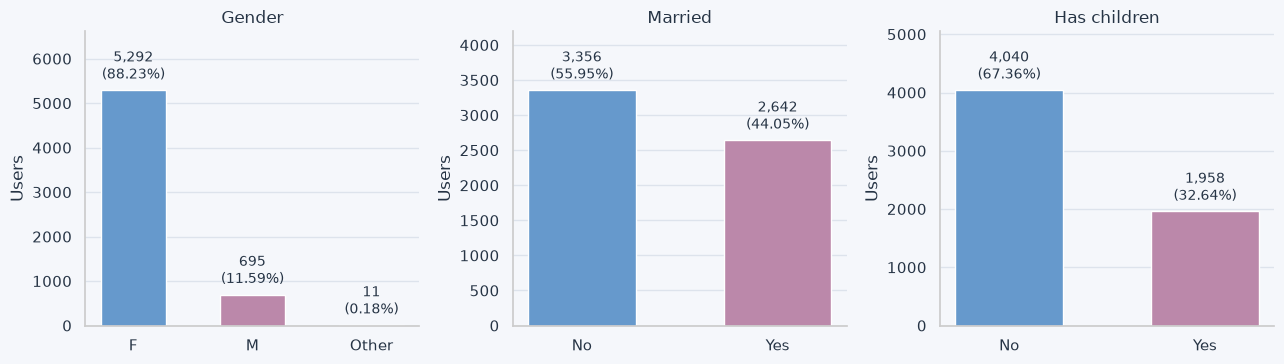

In [8]:
# prepare category tables and charts
# kategorietabellen und diagramme vorbereiten
chart_settings = [
    ("gender", ["F", "M", "O"], ["F", "M", "Other"], "Gender"),
    ("married", [False, True], ["No", "Yes"], "Married"),
    ("has_children", [False, True], ["No", "Yes"], "Has children"),
]

html_tables = []

for column, order, labels, title in chart_settings:
    counts = (
        users_work[column]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="users")
    )
    counts["share_pct"] = counts["users"] / len(users_work) * 100

    styled = style_overview(
        counts,
        title,
        {
            "users": "{:,.0f}",
            "share_pct": "{:.2f}%",
        },
    )

    # apply the shared pastel palette to table headers
    # gemeinsame pastellpalette für tabellenüberschriften verwenden
    styled = styled.set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["table_header"]),
                ("color", COLORS["text"]),
            ],
        },
      {
    "selector": "caption",
    "props": [
        ("color", COLORS["ice"]),
        ("font-size", "18px"),
        ("font-weight", "700"),
    ],
},
        {
            "selector": "td",
            "props": [
                ("background-color", COLORS["background"]),
                ("color", COLORS["text"]),
            ],
        },
    ], overwrite=False)

    html_tables.append(
        f'<div style="min-width: 0;">{styled.to_html()}</div>'
    )

# display three tables in one row
# drei tabellen in einer zeile anzeigen
display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(3, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(html_tables)
    + "</div>"
))

# display three charts underneath in the same order
# drei diagramme darunter in derselben reihenfolge anzeigen
fig, axes = plt.subplots(ncols=3, figsize=(13, 3.8))

for ax, (column, order, labels, title) in zip(axes, chart_settings):
    counts = (
        users_work[column]
        .value_counts()
        .reindex(order, fill_value=0)
    )
    percentages = counts / len(users_work) * 100

    bars = ax.bar(
        labels,
        counts.to_numpy(),
        color=PALETTE[:len(order)],
        width=0.55,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{count:,.0f}\n({percentage:.2f}%)"
            for count, percentage in zip(counts, percentages)
        ],
        padding=5,
        fontsize=10,
    )

    ax.set(
        title=title,
        ylabel="Users",
        ylim=(0, max(counts.max(), 1) * 1.25),
    )
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### 3.3 Validate text values / Textwerte prüfen

Check all user text columns for empty values, surrounding whitespace
and variants that differ only in capitalization or whitespace.

Alle Textspalten auf leere Werte, äußere Leerzeichen und Varianten prüfen,
die sich nur durch Groß-/Kleinschreibung oder Leerzeichen unterscheiden.

In [9]:
# inspect text columns without changing the working data
# textspalten prüfen, ohne die arbeitsdaten zu verändern
text_checks = []
text_variants = {}

for column in users_work.select_dtypes(
    include=["object", "string", "str"]
).columns:
    values = users_work[column].astype("string")
    stripped = values.str.strip()
    normalized = stripped.str.casefold()

    variants = pd.DataFrame({
        "original": values,
        "normalized": normalized,
    }).dropna().drop_duplicates()

    variant_counts = variants.groupby("normalized")["original"].nunique()
    variant_groups = variant_counts[variant_counts > 1].index

    text_checks.append({
        "column": column,
        "unique_values": values.nunique(),
        "blank_values": stripped.eq("").sum(),
        "surrounding_whitespace": values.ne(stripped).sum(),
        "variant_groups": len(variant_groups),
    })

    text_variants[column] = variants[
        variants["normalized"].isin(variant_groups)
    ].sort_values(["normalized", "original"])

display(style_overview(
    pd.DataFrame(text_checks),
    "users — Text validation",
    {
        "unique_values": "{:,.0f}",
        "blank_values": "{:,.0f}",
        "surrounding_whitespace": "{:,.0f}",
        "variant_groups": "{:,.0f}",
    },
))

column,unique_values,blank_values,surrounding_whitespace,variant_groups
gender,3,0,0,0
home_country,2,0,0,0
home_city,105,0,0,0
home_airport,159,0,0,0


### Standardize countries and cities / Länder und Städte vereinheitlichen

Standardize country names to USA and Canada and apply title case
to city names. Preserve the original values in users.

Ländernamen auf USA und Canada vereinheitlichen und Stadtwörter
mit großen Anfangsbuchstaben darstellen. Die Originalwerte
bleiben in users erhalten.

In [10]:
# preserve values for the before-and-after comparison
# werte für den vorher-nachher-vergleich erhalten
location_before = users_work[
    ["home_country", "home_city"]
].copy()

# standardize known country names
# bekannte ländernamen vereinheitlichen
country_text = (
    users_work["home_country"]
    .astype("string")
    .str.strip()
)

country_mapping = {
    "usa": "USA",
    "canada": "Canada",
}

users_work["home_country"] = (
    country_text.str.casefold()
    .map(country_mapping)
    .fillna(country_text)
)

# capitalize each city word
# jedes wort der stadtnamen mit großbuchstaben beginnen
users_work["home_city"] = (
    users_work["home_city"]
    .astype("string")
    .str.strip()
    .str.title()
)

# display changed spellings side by side
# geänderte schreibweisen nebeneinander anzeigen
html_tables = []

for column in ["home_country", "home_city"]:
    comparison = pd.DataFrame({
        "before": location_before[column],
        "after": users_work[column],
    })

    changed = comparison["before"].ne(
        comparison["after"]
    ).fillna(False)

    changes = (
        comparison.loc[changed]
        .value_counts()
        .reset_index(name="affected_users")
    )

    html_tables.append(
        '<div style="min-width: 0; overflow-x: auto;">'
        + style_overview(
            changes,
            f"{column} — Spelling changes",
            {"affected_users": "{:,.0f}"},
        ).to_html()
        + "</div>"
    )

display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(2, minmax(0, 1fr)); '
    'gap: 24px; align-items: start;">'
    + "".join(html_tables)
    + "</div>"
))

before,after,affected_users
usa,USA,"4,991"
canada,Canada,"1,007"
before,after,affected_users
new york,New York,680
los angeles,Los Angeles,325
toronto,Toronto,225
chicago,Chicago,195
houston,Houston,185
montreal,Montreal,166
san antonio,San Antonio,132


### Enrich home-airport information / Heimatflughäfen ergänzen

Use airportsdata to add airport names, cities and country codes.
Check unmatched airport codes before comparing cities.
The reference data reflects current information, not necessarily 2023.

Mit airportsdata Flughafennamen, Städte und Ländercodes ergänzen.
Nicht zugeordnete Flughafencodes vor dem Städtevergleich prüfen.
Die Referenzdaten entsprechen dem aktuellen Stand, nicht zwingend 2023.

In [11]:
# load airport reference data indexed by IATA code
# flughafenreferenzdaten nach IATA-code laden
airport_reference = pd.DataFrame.from_dict(
    airportsdata.load("IATA"),
    orient="index",
)

# normalize lookup keys without replacing the original airport codes
# suchschlüssel vereinheitlichen, ohne originalcodes zu ersetzen
airport_keys = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# add reference fields to the working copy
# referenzfelder zur arbeitskopie hinzufügen
for source, target in [
    ("name", "home_airport_name"),
    ("city", "home_airport_city"),
    ("country", "home_airport_country_code"),
]:
    users_work[target] = (
        airport_keys
        .map(airport_reference[source])
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# check lookup coverage separately from field completeness
# zuordnungsquote getrennt von der feldvollständigkeit prüfen
matched = airport_keys.isin(airport_reference.index)

lookup_summary = pd.DataFrame({
    "check": [
        "Total users",
        "Users with matched airport code",
        "Users with unmatched airport code",
        "Users without airport name",
        "Users without airport city",
    ],
    "users": [
        len(users_work),
        matched.sum(),
        (~matched).sum(),
        users_work["home_airport_name"].isna().sum(),
        users_work["home_airport_city"].isna().sum(),
    ],
})

unmatched_codes = (
    airport_keys.loc[~matched]
    .value_counts(dropna=False)
    .rename_axis("airport_code")
    .reset_index(name="users")
)

# display validation tables side by side
# prüftabellen nebeneinander anzeigen
table_specs = [
    (lookup_summary, "Airport lookup — Coverage"),
    (unmatched_codes, "Airport lookup — Unmatched codes"),
]

display(HTML(
    '<div style="display: flex; gap: 24px; '
    'align-items: flex-start; flex-wrap: wrap;">'
    + "".join(
        "<div>"
        + style_overview(
            df, title, {"users": "{:,.0f}"}
        ).to_html()
        + "</div>"
        for df, title in table_specs
    )
    + "</div>"
))

display(style_overview(
    users_work[
        ["home_airport", "home_airport_name", "home_airport_city"]
    ].drop_duplicates().head(10),
    "Airport lookup — Preview",
))

check,users
Total users,"5,998"
Users with matched airport code,"5,752"
Users with unmatched airport code,246
Users without airport name,246
Users without airport city,270
airport_code,users
YKZ,66
YZD,53
YED,33
YXD,28


home_airport,home_airport_name,home_airport_city
LGA,Laguardia Airport,New York
MCI,Kansas City International Airport,Kansas City
TCM,Mcchord Field (Joint Base Lewis-Mcchord) Airport,Tacoma
BOS,General Edward Lawrence Logan International Airport,Boston
TNT,Dade-Collier Training And Transition Airport,Miami
LAX,Los Angeles International Airport,Los Angeles
SNA,John Wayne/Orange County Airport,Santa Ana
BIF,Biggs Army Air Field (Fort Bliss) Airport,Fort Bliss/El Paso/
AUS,Austin-Bergstrom International Airport,Austin
BHM,Birmingham-Shuttlesworth International Airport,Birmingham


### Inspect potentially military airports
### Möglicherweise militärische Flughäfen untersuchen

Search airport names for military-related terms and inspect linked
flight records and booking indicators in the current analysis group.
This is an exploratory check using data not yet fully validated.

Flughafennamen nach militärischen Begriffen durchsuchen und zugehörige
Flugdatensätze sowie Buchungsindikatoren der aktuellen Analysegruppe prüfen.
Dies ist eine explorative Prüfung noch nicht vollständig validierter Daten.

In [12]:
# inspect both home airports and flight origins
# sowohl heimatflughäfen als auch abflughäfen untersuchen
home_codes = (
    users_work["home_airport"]
    .astype("string").str.strip().str.upper()
)
origin_codes = (
    flights_work["origin_airport"]
    .astype("string").str.strip().str.upper()
)

airport_codes = pd.Index(
    pd.concat([home_codes, origin_codes]).dropna().unique()
)

airport_candidates = pd.DataFrame({
    "airport_code": airport_codes,
})

airport_candidates["airport_name"] = (
    airport_candidates["airport_code"]
    .map(airport_reference["name"])
)

# name-based screening, not a confirmed classification
# namensbasierte suche, keine bestätigte klassifizierung
military_pattern = (
    r"\b(?:army|navy|naval|air\s*force|airforce|military|"
    r"afb|aaf|nas|air\s*base|joint\s*base|marine\s*corps|"
    r"rcaf|cfb)\b"
)

military_airports = airport_candidates.loc[
    airport_candidates["airport_name"].str.contains(
        military_pattern,
        case=False,
        regex=True,
        na=False,
    )
].copy()

# identify trips with an explicit flight-booking indicator
# reisen mit ausdrücklichem flugbuchungsindikator identifizieren
flight_booking_sessions = sessions_work.loc[
    sessions_work["flight_booked"].eq(True)
    & sessions_work["trip_id"].notna(),
    ["user_id", "trip_id"],
].drop_duplicates()

booking_trip_ids = flight_booking_sessions["trip_id"].unique()

results = []

for airport in military_airports.itertuples(index=False):
    origin_flights = flights_work.loc[
        origin_codes.eq(airport.airport_code).fillna(False)
    ]

    booked_origin_flights = origin_flights.loc[
        origin_flights["trip_id"].isin(booking_trip_ids)
    ]

    booking_users = flight_booking_sessions.loc[
        flight_booking_sessions["trip_id"].isin(
            booked_origin_flights["trip_id"]
        ),
        "user_id",
    ].nunique()

    results.append({
        "airport_code": airport.airport_code,
        "airport_name": airport.airport_name,
        "home_users": home_codes.eq(airport.airport_code).sum(),
        "origin_flight_records": len(origin_flights),
        "trips_with_booking_flag": (
            booked_origin_flights["trip_id"].nunique()
        ),
        "booking_users": booking_users,
    })

military_airport_check = pd.DataFrame(
    results,
    columns=[
        "airport_code",
        "airport_name",
        "home_users",
        "origin_flight_records",
        "trips_with_booking_flag",
        "booking_users",
    ],
).sort_values(
    ["trips_with_booking_flag", "airport_code"],
    ascending=[False, True],
)

display(style_overview(
    military_airport_check,
    "Potential military airports — Exploratory booking check",
    {
        "home_users": "{:,.0f}",
        "origin_flight_records": "{:,.0f}",
        "trips_with_booking_flag": "{:,.0f}",
        "booking_users": "{:,.0f}",
    },
))

airport_code,airport_name,home_users,origin_flight_records,trips_with_booking_flag,booking_users
LUF,Luke Afb Airport,60,134,134,50
RND,Randolph Afb Airport,46,126,126,42
NZY,North Island Nas (Halsey Field) Airport,50,113,113,42
BIF,Biggs Army Air Field (Fort Bliss) Airport,34,82,82,30
LSV,Nellis Afb Airport,25,64,64,22
DMA,Davis Monthan Afb Airport,22,63,63,22
OFF,Offutt Afb Airport,30,63,63,26
TIK,Tinker Afb Airport,24,63,63,22
TCM,Mcchord Field (Joint Base Lewis-Mcchord) Airport,21,40,40,20
MXF,Maxwell Afb Airport,23,37,37,18


**English:** Flight bookings in our analysis group reference all listed airports
with military-related names as departure airports.

**Deutsch:** Flugbuchungen unserer Analysegruppe verweisen auf alle aufgeführten
Flughäfen mit militärischen Namensbestandteilen als Abflughäfen.

In [13]:
# remove airport names after inspection; retain codes and cities
# flughafennamen nach der prüfung entfernen; codes und städte behalten
users_work.drop(
    columns=["home_airport_name"],
    errors="ignore",
    inplace=True,
)

### Complete researched airport cities / Recherchierte Flughafenstädte ergänzen

Fill missing airport cities using externally researched locations.
Require both the airport code and matching source coordinates.
Preserve the original codes, coordinates and users' home cities.

Fehlende Flughafenstädte anhand extern recherchierter Standorte ergänzen.
Flughafencode und vorhandene Koordinaten müssen zur Zuordnung passen.
Originalcodes, Koordinaten und Wohnorte bleiben erhalten.

In [14]:
# researched locations and expected coordinates from the source CSV
# recherchierte standorte und erwartete koordinaten aus der original-CSV
airport_city_corrections = [
    ("AKR", "Akron", 41.038, -81.467),
    ("YAV", "St. Andrews", 50.056, -97.032),
    ("YAW", "Halifax", 44.640, -63.499),
    ("YED", "Edmonton", 53.667, -113.467),
    ("YKZ", "Markham", 43.862, -79.370),
    ("YXD", "Edmonton", 53.573, -113.521),
    ("YZD", "Toronto", 43.742, -79.466),
]

airport_keys = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

correction_results = []

for code, city, latitude, longitude in airport_city_corrections:
    # only fill missing cities where code and coordinates agree
    # nur fehlende städte bei passendem code und koordinaten ergänzen
    mask = (
        airport_keys.eq(code).fillna(False)
        & users_work["home_airport_city"].isna()
        & np.isclose(
            users_work["home_airport_lat"],
            latitude,
            atol=0.001,
            rtol=0,
        )
        & np.isclose(
            users_work["home_airport_lon"],
            longitude,
            atol=0.001,
            rtol=0,
        )
    )

    correction_results.append({
        "airport_code": code,
        "airport_city": city,
        "updated_users": mask.sum(),
    })

    users_work.loc[mask, "home_airport_city"] = city

# display researched additions only
# ausschließlich recherchierte ergänzungen anzeigen
display(style_overview(
    pd.DataFrame(correction_results),
    "Airport cities — Researched additions",
    {"updated_users": "{:,.0f}"},
))

airport_code,airport_city,updated_users
AKR,Akron,20
YAV,St. Andrews,26
YAW,Halifax,20
YED,Edmonton,33
YKZ,Markham,66
YXD,Edmonton,28
YZD,Toronto,53


### Complete remaining airport cities / Verbleibende Flughafenstädte ergänzen

External research and source coordinates identify NZC as Cecil Airport
in Jacksonville, Florida, and NCA as MCAS New River in Jacksonville,
North Carolina. Correct the airport cities and country codes.

Externe Recherche und Originalkoordinaten ordnen NZC dem Cecil Airport
in Jacksonville, Florida, und NCA dem MCAS New River in Jacksonville,
North Carolina, zu. Flughafenstädte und Ländercodes korrigieren.

In [15]:
# correct reference assignments using the source coordinates
# referenzzuordnungen anhand der originalkoordinaten korrigieren
additional_corrections = [
    ("NZC", 30.219, -81.876),
    ("NCA", 34.708, -77.439),
]

correction_summary = []

for code, latitude, longitude in additional_corrections:
    mask = (
        airport_keys.eq(code).fillna(False)
        & np.isclose(
            users_work["home_airport_lat"],
            latitude, atol=0.001, rtol=0,
        )
        & np.isclose(
            users_work["home_airport_lon"],
            longitude, atol=0.001, rtol=0,
        )
    )

    users_work.loc[mask, "home_airport_city"] = "Jacksonville"
    users_work.loc[mask, "home_airport_country_code"] = "US"

    correction_summary.append({
        "airport_code": code,
        "airport_city": "Jacksonville",
        "matched_users": mask.sum(),
    })

display(style_overview(
    pd.DataFrame(correction_summary),
    "Airport cities — Additional corrections",
    {"matched_users": "{:,.0f}"},
))

# check completeness of airport codes and airport cities
# vollständigkeit von flughafencodes und flughafenstädten prüfen
missing_codes = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

missing_cities = (
    users_work["home_airport_city"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

checks = [
    ("Airport codes", missing_codes),
    ("Airport cities", missing_cities),
]

cards = []

for title, missing in checks:
    passed = missing == 0
    background = "#DDEFEA" if passed else "#F5DFE3"
    text_color = "#24594D" if passed else "#8B3045"
    status = "✓ Complete" if passed else "✗ Missing values"

    cards.append(f"""
        <div style="
            flex: 1;
            min-width: 220px;
            padding: 22px;
            border-radius: 12px;
            background: {background};
            color: {text_color};
            font-family: Segoe UI, sans-serif;
        ">
            <div style="font-size: 18px; font-weight: 700;">
                {title}
            </div>
            <div style="font-size: 26px; font-weight: 700; margin: 12px 0;">
                {status}
            </div>
            <div>Missing: <strong>{missing:,}</strong></div>
            <div>Total users: <strong>{len(users_work):,}</strong></div>
        </div>
    """)

# check completeness of airport codes and airport cities
# vollständigkeit von flughafencodes und flughafenstädten prüfen
missing_codes = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

missing_cities = (
    users_work["home_airport_city"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

checks = [
    ("Airport codes", missing_codes),
    ("Airport cities", missing_cities),
]

cards = []

for title, missing in checks:
    passed = missing == 0
    background = "#DDEFEA" if passed else "#F5DFE3"
    text_color = "#24594D" if passed else "#8B3045"
    status = "✓ Complete" if passed else "✗ Missing values"

    cards.append(f"""
        <div style="
            flex: 1;
            min-width: 220px;
            padding: 22px;
            border-radius: 12px;
            background: {background};
            color: {text_color};
            font-family: Segoe UI, sans-serif;
        ">
            <div style="font-size: 18px; font-weight: 700;">
                {title}
            </div>
            <div style="font-size: 26px; font-weight: 700; margin: 12px 0;">
                {status}
            </div>
            <div>Missing: <strong>{missing:,}</strong></div>
            <div>Total users: <strong>{len(users_work):,}</strong></div>
        </div>
    """)

display(HTML(
    '<div style="display: flex; gap: 20px; flex-wrap: wrap;">'
    + "".join(cards)
    + "</div>"
))

airport_code,airport_city,matched_users
NZC,Jacksonville,14
NCA,Jacksonville,10


In [16]:
# remove the airport country code
# flughafen-ländercode entfernen
users_work.drop(
    columns=["home_airport_country_code"],
    errors="ignore",
    inplace=True,
)

In [17]:
display(style_overview(
    pd.DataFrame({
        "column": [
            column for column in users_work.columns
            if "airport" in column
        ]
    }),
    "users — Airport columns",
))

column
home_airport
home_airport_lat
home_airport_lon
home_airport_city


### Validate automatic airport assignments
### Automatische Flughafenzuordnungen prüfen

Compare source coordinates with the coordinates of automatically matched airports.
Flag distances above 5 km for inspection; this threshold does not prove an error.
The nine externally researched exceptions are excluded from this check.

Originalkoordinaten mit den Koordinaten automatisch zugeordneter Flughäfen
vergleichen. Abstände über 5 km zur Prüfung markieren; diese Grenze beweist
keinen Fehler. Die neun extern recherchierten Sonderfälle bleiben ausgenommen.

In [18]:
# inspect distinct source airports rather than individual users
# unterschiedliche ausgangsflughäfen statt einzelner nutzer prüfen
reviewed_codes = {
    "AKR", "YAV", "YAW", "YED", "YKZ", "YXD", "YZD", "NZC", "NCA"
}

airport_validation = (
    users_work[
        ["home_airport", "home_airport_lat", "home_airport_lon"]
    ]
    .drop_duplicates()
    .copy()
)

airport_validation["lookup_code"] = (
    airport_validation["home_airport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

airport_validation = airport_validation.loc[
    ~airport_validation["lookup_code"].isin(reviewed_codes)
].copy()

airport_validation["reference_lat"] = (
    airport_validation["lookup_code"].map(airport_reference["lat"])
)
airport_validation["reference_lon"] = (
    airport_validation["lookup_code"].map(airport_reference["lon"])
)

# calculate great-circle distance using the Haversine formula
# großkreisentfernung mit der Haversine-formel berechnen
lat_source = np.radians(airport_validation["home_airport_lat"])
lon_source = np.radians(airport_validation["home_airport_lon"])
lat_reference = np.radians(airport_validation["reference_lat"])
lon_reference = np.radians(airport_validation["reference_lon"])

a = (
    np.sin((lat_reference - lat_source) / 2) ** 2
    + np.cos(lat_source)
    * np.cos(lat_reference)
    * np.sin((lon_reference - lon_source) / 2) ** 2
)

airport_validation["distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
)

missing_reference = airport_validation[
    ["reference_lat", "reference_lon"]
].isna().any(axis=1)

needs_review = (
    missing_reference
    | airport_validation["distance_km"].gt(5)
)

# show the overall result as an HTML status card
# gesamtergebnis als HTML-statuskachel anzeigen
review_count = int(needs_review.sum())
background = "#DDEFEA" if review_count == 0 else "#F5DFE3"
text_color = "#24594D" if review_count == 0 else "#8B3045"

display(HTML(f"""
<div style="
    background: {background};
    color: {text_color};
    padding: 22px;
    border-radius: 12px;
    font-family: Segoe UI, sans-serif;
">
    <div style="font-size: 18px; font-weight: 700;">
        Automatic airport assignments — Coordinate check
    </div>
    <div style="font-size: 26px; font-weight: 700; margin: 12px 0;">
        {review_count} assignments to review
    </div>
    <div>Checked airport entries: <strong>{len(airport_validation):,}</strong></div>
    <div>Previously researched codes excluded: <strong>9</strong></div>
</div>
"""))

# display details only if assignments require inspection
# details nur bei prüfbedürftigen zuordnungen anzeigen
if review_count > 0:
    display(style_overview(
        airport_validation.loc[
            needs_review,
            [
                "home_airport",
                "home_airport_lat",
                "home_airport_lon",
                "reference_lat",
                "reference_lon",
                "distance_km",
            ],
        ].sort_values("distance_km", ascending=False),
        "Airport assignments — Review details",
        {"distance_km": "{:,.2f}"},
    ))

**Findings:** All 150 automatically matched airport entries have reference
coordinates within 5 km of the source coordinates. No additional assignments
were flagged. Nine researched exceptions were handled separately.
This supports airport identification.

**Erkenntnisse:** Bei allen 150 automatisch zugeordneten Flughafeneinträgen
liegen die Referenzkoordinaten höchstens 5 km von den Originalkoordinaten
entfernt. Keine weitere Zuordnung wurde markiert. Neun recherchierte
Sonderfälle wurden separat behandelt. Das stützt die Flughafenidentifikation.

In [19]:
# standardize researched airport city assignments
airport_city_corrections = {
    "UGN": "Waukegan",
    "BIF": "El Paso",
    "PIE": "Clearwater",
}

airport_codes = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

for airport_code, airport_city in airport_city_corrections.items():
    users_work.loc[
        airport_codes.eq(airport_code),
        "home_airport_city",
    ] = airport_city

### Compare home city and airport city
### Wohnort und Flughafenstadt vergleichen

Identify users whose home city and airport city have different names.
Different city names do not establish a long journey or a need for accommodation.
However, they may help identify potential target groups for incentives
such as a complimentary overnight stay or airport transfer.

Nutzer mit unterschiedlichen Wohnort- und Flughafenstadtnamen identifizieren.
Unterschiedliche Stadtnamen belegen weder eine weite Anfahrt noch Übernachtungsbedarf.
Sie können jedoch Hinweise auf mögliche Zielgruppen für Anreize wie
eine kostenlose Übernachtung oder einen Flughafentransfer liefern.

In [20]:
# normalize names for comparison without changing the display columns
# namen für den vergleich vereinheitlichen, ohne anzeigespalten zu verändern
# normalize city names and confirmed spelling variants
# stadtnamen und bestätigte schreibvarianten vereinheitlichen
def normalize_city_names(series):
    normalized = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
        .replace("", pd.NA)
    )

    spelling_aliases = {
        "st. louis": "st louis",
        "winston-salem": "winston salem",
        "st. petersburg": "st petersburg",
        "quebec": "quebec city",
        "québec": "quebec city",
        "québec city": "quebec city",
    }

    return normalized.replace(spelling_aliases)


home_city_key = normalize_city_names(users_work["home_city"])
airport_city_key = normalize_city_names(users_work["home_airport_city"])

users_work["home_city_matches_airport_city"] = (
    home_city_key.eq(airport_city_key).astype("boolean")
)

# summarize the comparison, including unknown results
# vergleich einschließlich unbekannter ergebnisse zusammenfassen
comparison = users_work["home_city_matches_airport_city"]

city_match_summary = pd.DataFrame({
    "result": [
        "Same city name",
        "Different city names",
        "Missing city information",
    ],
    "users": [
        comparison.eq(True).sum(),
        comparison.eq(False).sum(),
        comparison.isna().sum(),
    ],
})

city_match_summary["share_pct"] = (
    city_match_summary["users"] / len(users_work) * 100
)

# show the most frequent combinations with different names
# häufigste kombinationen mit unterschiedlichen namen anzeigen
different_city_pairs = (
    users_work.loc[
        comparison.eq(False).fillna(False),
        ["home_city", "home_airport_city", "home_airport"],
    ]
    .groupby(
        ["home_city", "home_airport_city", "home_airport"],
        dropna=False,
    )
    .size()
    .reset_index(name="users")
    .sort_values(
        ["users", "home_city", "home_airport"],
        ascending=[False, True, True],
    )
)

# display both tables side by side
# beide tabellen nebeneinander anzeigen
table_specs = [
    (
        city_match_summary,
        "Home city vs. airport city",
        {"users": "{:,.0f}", "share_pct": "{:.2f}%"},
    ),
    (
        different_city_pairs,
        "Different city names — All combinations",
        {"users": "{:,.0f}"},
    ),
]

display(HTML(
    '<div style="display: flex; gap: 24px; '
    'align-items: flex-start; overflow-x: auto;">'
    + "".join(
        '<div style="flex-shrink: 0;">'
        + style_overview(df, title, formats).to_html()
        + "</div>"
        for df, title, formats in table_specs
    )
    + "</div>"
))

### User location data — Cleaning summary
### Standortdaten der Nutzer — Zusammenfassung der Bereinigung

Country and city names were standardized. Missing airport cities were
supplemented through external research using airport codes and coordinates.
Selected combined location names were reviewed and clarified.

The column `home_city_matches_airport_city` records whether the standardized
city names match: 5,436 users (90.63%) have matching names, while 562 users
(9.37%) have different names. No city information is missing.

Länder- und Städtenamen wurden vereinheitlicht. Fehlende Flughafenstädte
wurden anhand von Flughafenkürzeln und Koordinaten extern recherchiert und
ergänzt. Ausgewählte zusammengesetzte Ortsangaben wurden geprüft und präzisiert.

Die Spalte `home_city_matches_airport_city` zeigt, ob die vereinheitlichten
Stadtnamen übereinstimmen: Bei 5.436 Nutzern (90,63 %) stimmen sie überein,
bei 562 Nutzern (9,37 %) unterscheiden sie sich. Es fehlen keine Stadtangaben.

### 3.4 Validate user dates / Datumsangaben prüfen

Use the latest observed session date as the reference date.
Check birthdates and sign-up dates for chronological inconsistencies.

Das Datum der letzten beobachteten Session als Stichtag verwenden.
Geburts- und Anmeldedaten auf zeitliche Widersprüche prüfen.

In [21]:
# derive the reference date from the session data
# stichtag aus den session-daten ableiten
reference_date = pd.to_datetime(
    sessions_work["session_start"], errors="raise"
).max().normalize()

# check chronological consistency without removing records
# zeitliche plausibilität prüfen, ohne datensätze zu entfernen
date_validation = pd.DataFrame([
    {
        "check": "Birthdate after reference date",
        "affected_users": (
            users_work["birthdate"] > reference_date
        ).sum(),
    },
    {
        "check": "Sign-up before birthdate",
        "affected_users": (
            users_work["sign_up_date"] < users_work["birthdate"]
        ).sum(),
    },
    {
        "check": "Sign-up after reference date",
        "affected_users": (
            users_work["sign_up_date"] > reference_date
        ).sum(),
    },
])

display(style_overview(
    date_validation,
    f"users — Date plausibility | {reference_date:%Y-%m-%d}",
    {"affected_users": "{:,.0f}"},
))

check,affected_users
Birthdate after reference date,0
Sign-up before birthdate,0
Sign-up after reference date,0


### 3.5 Calculate age / Alter berechnen

Calculate completed years of age at the reference date.
Inspect the age range and birth-year distribution, especially 2006.

Das Alter in vollendeten Jahren am Stichtag berechnen.
Altersspanne und Geburtsjahrverteilung untersuchen, insbesondere 2006.

metric,age
Minimum,16.0
Median,41.0
Mean,40.9
Maximum,88.0


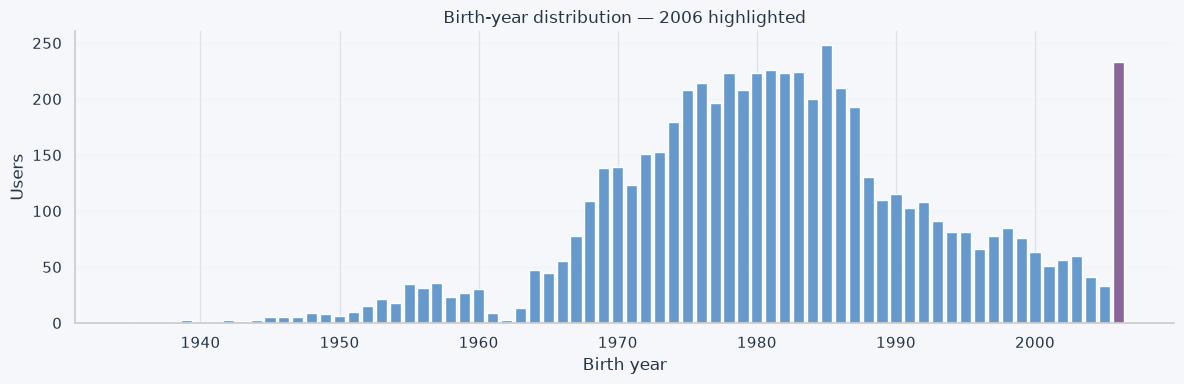

In [22]:
# subtract one year if the birthday has not yet occurred this year
# ein jahr abziehen, falls der geburtstag dieses jahr noch bevorsteht
birthdates = users_work["birthdate"]

birthday_pending = (
    (birthdates.dt.month > reference_date.month)
    | (
        (birthdates.dt.month == reference_date.month)
        & (birthdates.dt.day > reference_date.day)
    )
)

users_work["age"] = (
    reference_date.year
    - birthdates.dt.year
    - birthday_pending.astype(int)
).astype("Int64")

age_summary = pd.DataFrame({
    "metric": ["Minimum", "Median", "Mean", "Maximum"],
    "age": [
        users_work["age"].min(),
        users_work["age"].median(),
        users_work["age"].mean(),
        users_work["age"].max(),
    ],
})

display(style_overview(
    age_summary,
    "users — Age at reference date",
    {"age": "{:.1f}"},
))

birth_year_counts = (
    birthdates.dt.year
    .value_counts()
    .sort_index()
    .rename_axis("birth_year")
    .reset_index(name="users")
)

fig, ax = plt.subplots(figsize=(12, 4))
colors = [
    COLORS["highlight"] if year == 2006 else COLORS["blue"]
    for year in birth_year_counts["birth_year"]
]

ax.bar(
    birth_year_counts["birth_year"],
    birth_year_counts["users"],
    color=colors,
)
ax.set(
    title="Birth-year distribution — 2006 highlighted",
    xlabel="Birth year",
    ylabel="Users",
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

English: The 2006 birth cohort is among the most frequent in the analysis group and shows a pronounced increase compared with neighboring birth years. The cause remains unclear.
Deutsch: Der Geburtsjahrgang 2006 gehört zu den häufigsten in der Analysegruppe und zeigt einen deutlichen Anstieg gegenüber benachbarten Jahrgängen. Die Ursache ist noch unklar.

### 3.6 Investigate birth year 2006 / Geburtsjahr 2006 untersuchen

Measure the frequency of birth year 2006 and inspect its birthdates.
Repeated dates may suggest a default value, but do not establish a data error.

Die Häufigkeit des Geburtsjahrs 2006 und die einzelnen Geburtsdaten prüfen.
Wiederholte Daten könnten auf einen Standardwert hindeuten, belegen aber keinen Datenfehler.

In [23]:
# select users born in 2006
# nutzer mit geburtsjahr 2006 auswählen
users_2006 = users_work.loc[
    users_work["birthdate"].dt.year.eq(2006)
].copy()

# summarize the size and birthdate diversity of this group
# größe und anzahl unterschiedlicher geburtsdaten zusammenfassen
summary_2006 = pd.DataFrame({
    "users": [len(users_2006)],
    "share_pct": [len(users_2006) / len(users_work) * 100],
    "distinct_birthdates": [
        users_2006["birthdate"].dt.date.nunique()
    ],
})

# compare neighboring birth years
# benachbarte geburtsjahrgänge vergleichen
neighboring_years = (
    users_work["birthdate"].dt.year
    .value_counts()
    .reindex(range(2002, 2007), fill_value=0)
    .rename_axis("birth_year")
    .reset_index(name="users")
)

# identify the most frequent birthdates within 2006
# die häufigsten geburtsdaten innerhalb von 2006 ermitteln
birthdate_counts_2006 = (
    users_2006["birthdate"].dt.date
    .value_counts()
    .rename_axis("birthdate")
    .reset_index(name="users")
    .sort_values(
        ["users", "birthdate"],
        ascending=[False, True],
    )
)

# display related tables side by side using the shared design
# zusammengehörige tabellen im gemeinsamen design nebeneinander anzeigen
table_specs = [
    (
        summary_2006,
        "Birth year 2006",
        {
            "users": "{:,.0f}",
            "share_pct": "{:.2f}%",
            "distinct_birthdates": "{:,.0f}",
        },
    ),
    (
        neighboring_years,
        "Birth years 2002–2006",
        {"users": "{:,.0f}"},
    ),
    (
        birthdate_counts_2006.head(10),
        "Most frequent birthdates in 2006",
        {"users": "{:,.0f}"},
    ),
]

html_tables = [
    (
        '<div style="min-width: 0;">'
        + style_overview(df, title, formats).to_html()
        + "</div>"
    )
    for df, title, formats in table_specs
]

display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(3, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(html_tables)
    + "</div>"
))

In [24]:
# remove age calculated at the reference date
users_work.drop(columns=["age"], errors="ignore", inplace=True)

### 3.7 Validate airport coordinates / Flughafenkoordinaten prüfen

Check coordinate ranges and whether each home airport has consistent coordinates.
Valid ranges alone do not confirm the actual airport location.

Koordinatenbereiche und die Einheitlichkeit der Koordinaten je Heimatflughafen prüfen.
Gültige Wertebereiche bestätigen allein noch nicht den tatsächlichen Flughafenstandort.

In [25]:
# check missing coordinates and valid geographic ranges
# fehlende koordinaten und gültige geografische wertebereiche prüfen
lat = users_work["home_airport_lat"]
lon = users_work["home_airport_lon"]

coordinate_checks = pd.DataFrame({
    "check": [
        "Missing latitude",
        "Missing longitude",
        "Latitude outside [-90, 90]",
        "Longitude outside [-180, 180]",
        "Both coordinates equal zero",
    ],
    "affected_users": [
        lat.isna().sum(),
        lon.isna().sum(),
        (lat.notna() & ~lat.between(-90, 90)).sum(),
        (lon.notna() & ~lon.between(-180, 180)).sum(),
        (lat.eq(0) & lon.eq(0)).sum(),
    ],
})

# count distinct coordinate pairs for each airport
# unterschiedliche koordinatenpaare je flughafen zählen
airport_pairs = users_work[
    ["home_airport", "home_airport_lat", "home_airport_lon"]
].drop_duplicates()

airport_coordinate_counts = (
    airport_pairs.groupby("home_airport")
    .size()
    .rename("coordinate_pairs")
    .reset_index()
)

inconsistent_airports = airport_coordinate_counts.loc[
    airport_coordinate_counts["coordinate_pairs"] > 1
]

table_specs = [
    (
        coordinate_checks,
        "Airport coordinate checks",
        {"affected_users": "{:,.0f}"},
    ),
    (
        inconsistent_airports,
        "Airports with multiple coordinate pairs",
        {"coordinate_pairs": "{:,.0f}"},
    ),
]

display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(2, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(
        '<div>'
        + style_overview(df, title, formats).to_html()
        + "</div>"
        for df, title, formats in table_specs
    )
    + "</div>"
))

check,affected_users
Missing latitude,0
Missing longitude,0
"Latitude outside [-90, 90]",0
"Longitude outside [-180, 180]",0
Both coordinates equal zero,0
home_airport,coordinate_pairs


**English:** Home-airport coordinates are complete, within valid ranges
and consistent per airport. Actual locations have not been externally verified.

**Deutsch:** Die Heimatflughafen-Koordinaten sind vollständig, liegen in gültigen
Bereichen und sind je Flughafen konsistent. Die tatsächlichen Standorte wurden
nicht extern überprüft.

### 3.8 Sessions before sign-up / Sessions vor der Anmeldung

Compare each user’s first session in the analysis period with their sign-up date.
If sign-up dates contain no time, compare calendar dates.

Die erste Session jedes Nutzers im Analysezeitraum mit dem Anmeldedatum vergleichen.
Wenn das Anmeldedatum keine Uhrzeit enthält, vergleichen wir Kalendertage.

In [26]:
# find each user's first session within the analysis period
# erste session je nutzer innerhalb des analysezeitraums ermitteln
first_sessions = (
    sessions_work
    .assign(
        session_start=pd.to_datetime(
            sessions_work["session_start"], errors="raise"
        )
    )
    .groupby("user_id", as_index=False)["session_start"]
    .min()
    .rename(columns={"session_start": "first_session_start"})
)

# join session dates to user profiles without modifying the source tables
# session-daten mit nutzerprofilen verbinden, ohne die quellen zu verändern
signup_check = users_work[
    ["user_id", "sign_up_date"]
].merge(
    first_sessions,
    on="user_id",
    how="left",
    validate="one_to_one",
)

signup_check["session_before_signup"] = (
    signup_check["first_session_start"].dt.normalize()
    < signup_check["sign_up_date"].dt.normalize()
)

summary = pd.DataFrame({
    "check": [
        "Users without a matching session",
        "Users with a session date before sign-up",
    ],
    "affected_users": [
        signup_check["first_session_start"].isna().sum(),
        signup_check["session_before_signup"].sum(),
    ],
})

display(style_overview(
    summary,
    "users — Session and sign-up consistency",
    {"affected_users": "{:,.0f}"},
))

# show examples only if inconsistencies exist
# beispiele nur anzeigen, falls widersprüche vorhanden sind
if signup_check["session_before_signup"].any():
    display(style_overview(
        signup_check.loc[
            signup_check["session_before_signup"],
            ["user_id", "sign_up_date", "first_session_start"],
        ].head(10),
        "Examples — Sessions before sign-up",
    ))

check,affected_users
Users without a matching session,0
Users with a session date before sign-up,0


### 3.9 Marital status and children / Familienstand und Kinder

Compare the four combinations of marital status and children.
Labels show user counts and percentages within each marital-status group.
Not married does not necessarily mean single.

Die vier Kombinationen aus Familienstand und Kinderstatus vergleichen.
Beschriftungen zeigen Nutzerzahlen und Anteile innerhalb des jeweiligen
Familienstands. Nicht verheiratet bedeutet nicht automatisch Single.

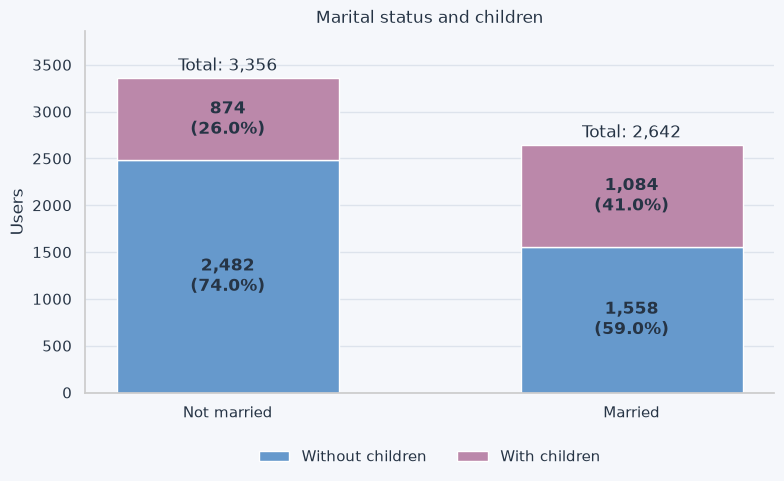

In [27]:
# count users for each combination
# nutzer je kombination zählen
family_counts = (
    pd.crosstab(users_work["married"], users_work["has_children"])
    .reindex(index=[False, True], columns=[False, True], fill_value=0)
)

family_shares = (
    family_counts
    .div(family_counts.sum(axis=1), axis=0)
    .mul(100)
)

# show all four combinations in one stacked chart
# alle vier kombinationen in einem gestapelten diagramm darstellen
fig, ax = plt.subplots(figsize=(8, 5))

positions = np.arange(len(family_counts))
bottom = np.zeros(len(family_counts))

for has_children, label, color in [
    (False, "Without children", COLORS["blue"]),
    (True, "With children", COLORS["lavender"]),
]:
    counts = family_counts[has_children].to_numpy()
    shares = family_shares[has_children].to_numpy()

    ax.bar(
        positions,
        counts,
        bottom=bottom,
        label=label,
        color=color,
        width=0.55,
    )

    for x, count, share, base in zip(positions, counts, shares, bottom):
        if count > 0:
            ax.text(
                x,
                base + count / 2,
                f"{count:,.0f}\n({share:.1f}%)",
                ha="center",
                va="center",
                color=COLORS["text"],
                fontweight="bold",
            )

    bottom += counts

# add the total number of users above each bar
# gesamtzahl der nutzer über jedem balken ergänzen
for x, total in zip(positions, bottom):
    ax.text(
        x,
        total + bottom.max() * 0.025,
        f"Total: {total:,.0f}",
        ha="center",
        color=COLORS["text"],
    )

ax.set_xticks(positions, ["Not married", "Married"])
ax.set(
    title="Marital status and children",
    ylabel="Users",
    ylim=(0, max(bottom.max(), 1) * 1.15),
)
ax.grid(axis="x", visible=False)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
)

plt.tight_layout()
plt.show()

In [28]:
print("Blue:", COLORS["blue"])
print("Lavender:", COLORS["lavender"])
print("Palette:", PALETTE)

Blue: #6699CC
Lavender: #BB88AA
Palette: ['#6699CC', '#BB88AA', '#66AA99', '#DDAA66']


**Findings:**
- Among 3,356 unmarried users, 874 (26.0%) have children.
- Among 2,642 married users, 1,084 (41.0%) have children.
- The share with children is about 15 percentage points higher among married users.
- These account characteristics do not establish who travels together.
- Unmarried does not necessarily mean single.

**Erkenntnisse:**
- Von 3.356 nicht verheirateten Nutzern haben 874 (26,0 %) Kinder.
- Von 2.642 verheirateten Nutzern haben 1.084 (41,0 %) Kinder.
- Der Kinderanteil liegt bei verheirateten Nutzern etwa 15 Prozentpunkte höher.
- Diese Kontomerkmale zeigen noch nicht, wer gemeinsam reist.
- Nicht verheiratet bedeutet nicht automatisch Single.

### 3.10 Gender, marital status and children
### Geschlecht, Familienstand und Kinder

Compare the share of users with and without children by gender,
separately for married and unmarried users. Each bar totals 100%.
Show group sizes; the Other category contains only 11 users overall.

Die Anteile mit und ohne Kinder nach Geschlecht vergleichen,
getrennt nach Familienstand. Jeder Balken ergibt 100 %.
Gruppengrößen anzeigen; Other umfasst insgesamt nur elf Nutzer.

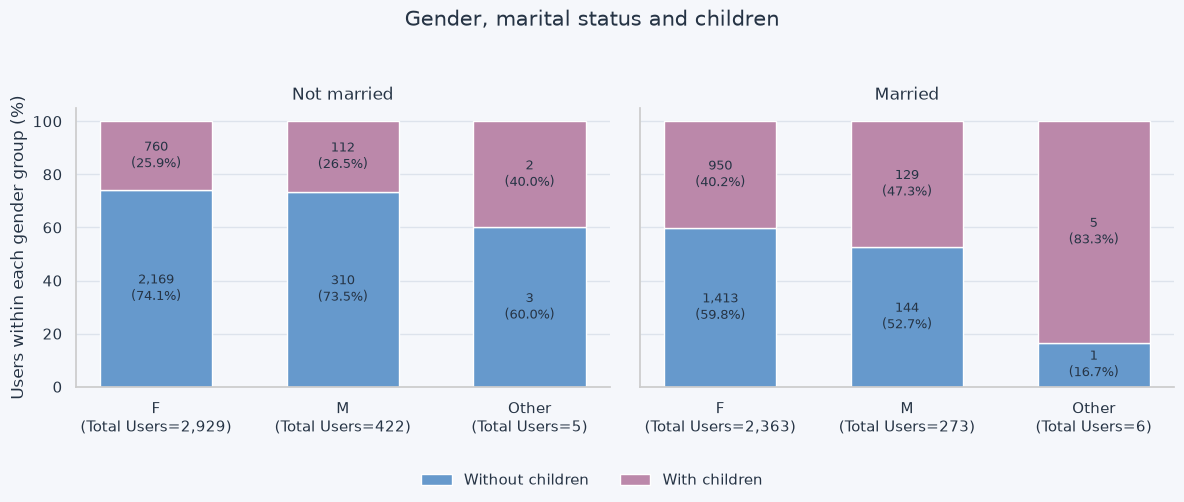

In [29]:
# compare children status by gender within each marital-status group
# kinderstatus nach geschlecht innerhalb der familienstandsgruppen vergleichen
gender_order = ["F", "M", "O"]
gender_labels = ["F", "M", "Other"]

fig, axes = plt.subplots(ncols=2, figsize=(12, 5), sharey=True)

for ax, married, title in zip(
    axes,
    [False, True],
    ["Not married", "Married"],
):
    subset = users_work.loc[users_work["married"].eq(married)]

    counts = (
        pd.crosstab(subset["gender"], subset["has_children"])
        .reindex(
            index=gender_order,
            columns=[False, True],
            fill_value=0,
        )
    )

    totals = counts.sum(axis=1)
    shares = counts.div(totals.replace(0, np.nan), axis=0).mul(100)
    bottom = np.zeros(len(gender_order))
    positions = np.arange(len(gender_order))

    for children, label, color in [
        (False, "Without children", COLORS["blue"]),
        (True, "With children", COLORS["lavender"]),
    ]:
        heights = shares[children].fillna(0).to_numpy()

        ax.bar(
            positions,
            heights,
            bottom=bottom,
            color=color,
            label=label,
            width=0.6,
        )

        for x, height, base, count in zip(
            positions, heights, bottom, counts[children]
        ):
            if height > 0:
                ax.text(
                    x,
                    base + height / 2,
                    f"{count:,.0f}\n({height:.1f}%)",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=COLORS["text"],
                )

        bottom += heights

    ax.set_xticks(
        positions,
        [
            f"{label}\n(Total Users={total:,.0f})"
            for label, total in zip(gender_labels, totals)
        ],
    )
    ax.set(title=title, ylim=(0, 105))
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Users within each gender group (%)")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
)

fig.suptitle("Gender, marital status and children", fontsize=15)
fig.tight_layout(rect=[0, 0.09, 1, 0.94])
plt.show()

**Findings:**
- Among unmarried users, the share with children is similar for women
  (25.9%) and men (26.5%).
- Among married users, 40.2% of women and 47.3% of men have children.
- For both women and men, the share with children is higher among
  married users than among unmarried users.
- The Other groups contain only five unmarried and six married users.
  Their percentages should not be generalized.
- These results describe account characteristics, not travel-party
  composition or who books on behalf of a family.

**Erkenntnisse:**
- Unter nicht verheirateten Nutzern ist der Kinderanteil bei Frauen
  (25,9 %) und Männern (26,5 %) ähnlich.
- Unter verheirateten Nutzern haben 40,2 % der Frauen und 47,3 % der Männer Kinder.
- Bei Frauen und Männern ist der Kinderanteil unter Verheirateten höher
  als unter nicht Verheirateten.
- Die Other-Gruppen umfassen nur fünf nicht verheiratete und sechs
  verheiratete Nutzer. Ihre Prozentwerte sind nicht verallgemeinerbar.
- Die Ergebnisse beschreiben Kontomerkmale, nicht die Zusammensetzung
  von Reisegruppen oder wer für eine Familie bucht.

### 3.11 Geographic distribution of users
### Geografische Verteilung der Nutzer

Compare the distribution of users by home country and identify the ten
most common home cities. Percentages refer to all users in the analysis group.

Die Verteilung der Nutzer nach Wohnsitzland vergleichen und die zehn
häufigsten Wohnorte ermitteln. Die Prozentangaben beziehen sich auf
alle Nutzer der Analysegruppe.

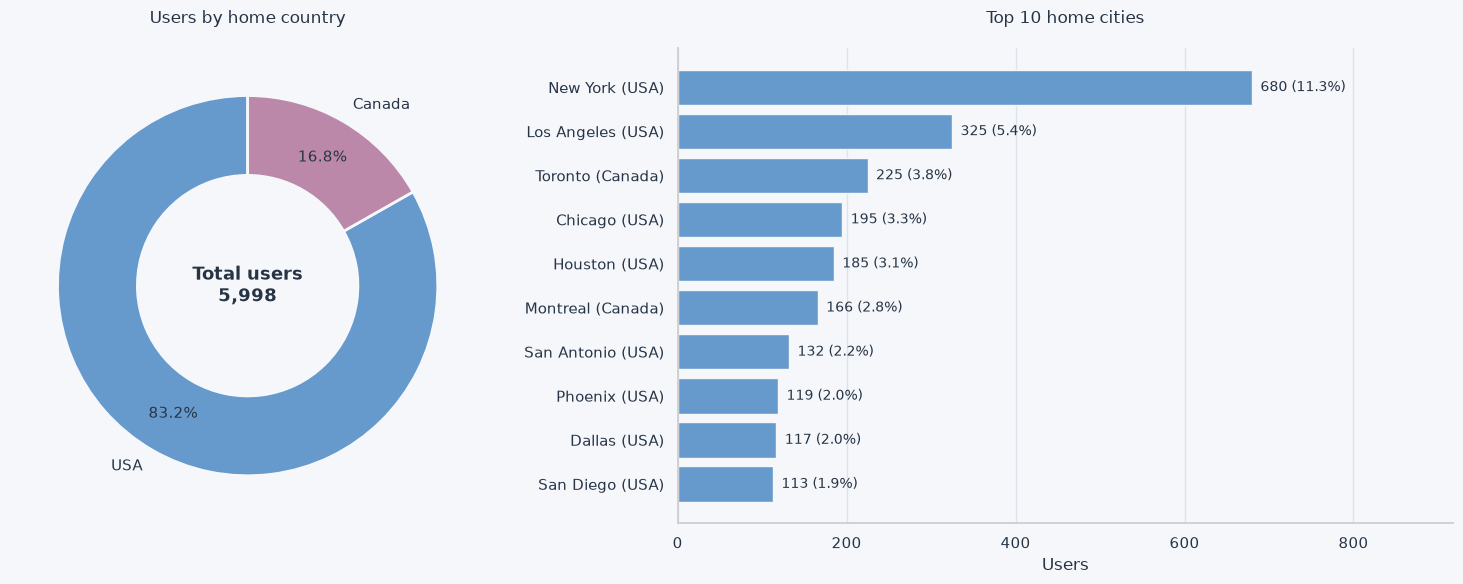

In [30]:
# summarize users by country and city
total_users = len(users_work)

country_summary = (
    users_work.groupby("home_country", dropna=False)
    .size()
    .reset_index(name="users")
    .sort_values(
        ["users", "home_country"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

country_summary["share_pct"] = (
    country_summary["users"] / total_users * 100
)

city_summary = (
    users_work.groupby(
        ["home_city", "home_country"],
        dropna=False,
    )
    .size()
    .reset_index(name="users")
    .sort_values(
        ["users", "home_city", "home_country"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

city_summary["share_pct"] = (
    city_summary["users"] / total_users * 100
)

top_cities = city_summary.head(10).copy()


# plot country shares and the most common home cities
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    gridspec_kw={"width_ratios": [1, 1.5]},
)

axes[0].pie(
    country_summary["users"],
    labels=country_summary["home_country"],
    colors=PALETTE[:len(country_summary)],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.42,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
    textprops={
        "color": COLORS["text"],
        "fontsize": 11,
    },
)

axes[0].text(
    0,
    0,
    f"Total users\n{total_users:,}",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=COLORS["text"],
)

axes[0].set_title("Users by home country", pad=18)

city_labels = (
    top_cities["home_city"]
    + " ("
    + top_cities["home_country"]
    + ")"
)

bars = axes[1].barh(
    city_labels,
    top_cities["users"],
    color=COLORS["blue"],
    edgecolor=COLORS["background"],
)

axes[1].invert_yaxis()
axes[1].set_title("Top 10 home cities", pad=18)
axes[1].set_xlabel("Users")
axes[1].set_ylabel("")
axes[1].grid(axis="y", visible=False)
axes[1].set_axisbelow(True)

bar_labels = [
    f"{count:,} ({share:.1f}%)"
    for count, share in zip(
        top_cities["users"],
        top_cities["share_pct"],
    )
]

axes[1].bar_label(
    bars,
    labels=bar_labels,
    padding=6,
    color=COLORS["text"],
    fontsize=10,
)

axes[1].set_xlim(
    0,
    top_cities["users"].max() * 1.35,
)

fig.tight_layout()
plt.show()

### 3.12 User sign-ups over time
### Nutzeranmeldungen im Zeitverlauf

Show monthly sign-ups among users in the analysis group.
The chart describes when these users registered, rather than the
overall growth of TravelTide.

Die monatlichen Anmeldungen der Nutzer unserer Analysegruppe darstellen.
Das Diagramm zeigt, wann sich diese Nutzer registriert haben,
und beschreibt nicht das gesamte Wachstum von TravelTide.

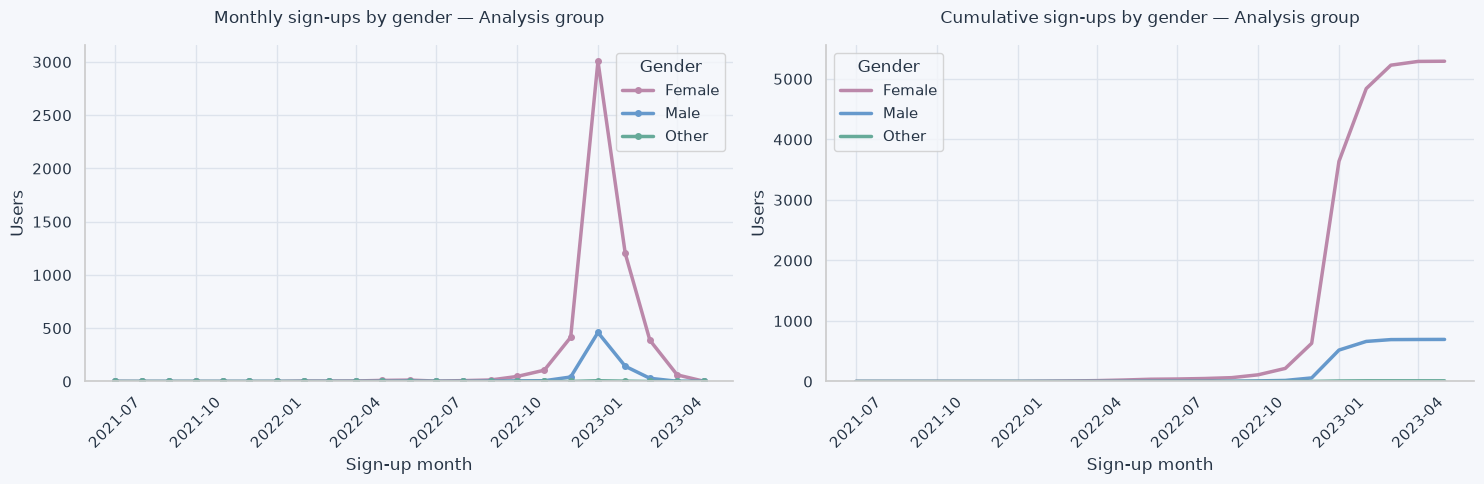

In [31]:
# count monthly sign-ups by gender
signup_months = users_work["sign_up_date"].dt.to_period("M")

month_range = pd.period_range(
    start=signup_months.min(),
    end=signup_months.max(),
    freq="M",
)

gender_order = ["F", "M", "O"]

gender_labels = {
    "F": "Female",
    "M": "Male",
    "O": "Other",
}

gender_colors = GENDER_COLORS

monthly_signups_by_gender = (
    users_work.assign(signup_month=signup_months)
    .groupby(["signup_month", "gender"])
    .size()
    .unstack("gender", fill_value=0)
    .reindex(
        index=month_range,
        columns=gender_order,
        fill_value=0,
    )
)

cumulative_signups_by_gender = monthly_signups_by_gender.cumsum()
month_dates = month_range.to_timestamp()

# compare monthly and cumulative sign-ups by gender
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for gender in gender_order:
    axes[0].plot(
        month_dates,
        monthly_signups_by_gender[gender].to_numpy(),
        label=gender_labels[gender],
        color=gender_colors[gender],
        linewidth=2.5,
        marker="o",
        markersize=4,
    )

    axes[1].plot(
        month_dates,
        cumulative_signups_by_gender[gender].to_numpy(),
        label=gender_labels[gender],
        color=gender_colors[gender],
        linewidth=2.5,
    )

axes[0].set_title(
    "Monthly sign-ups by gender — Analysis group",
    pad=16,
)

axes[1].set_title(
    "Cumulative sign-ups by gender — Analysis group",
    pad=16,
)

for ax in axes:
    ax.set_xlabel("Sign-up month")
    ax.set_ylabel("Users")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(bottom=0)
    ax.legend(title="Gender")

fig.tight_layout()
plt.show()

**Findings**

Female and male users both show a pronounced sign-up peak in December
2022, followed by a sharp decline. Female users account for most
registrations in absolute numbers. The Other category contains only
11 users, so its line remains close to zero.

The cumulative chart adds up registrations over time and ends at
5,292 female, 695 male and 11 Other users.

Users may have registered before the analysis period, which begins
on 4 January 2023. These charts describe the registration history
of the selected analysis group, not overall platform growth or
current user activity.

**Auswertung**

Sowohl bei Frauen als auch bei Männern zeigt sich ein deutlicher
Anmeldehöchststand im Dezember 2022. Danach sinken die monatlichen
Anmeldungen stark. Frauen stellen in absoluten Zahlen den größten
Teil der Anmeldungen. Die Kategorie Other umfasst nur elf Nutzer;
ihre Linie liegt deshalb nahe null.

Das kumulierte Diagramm summiert die Anmeldungen im Zeitverlauf.
Es endet bei 5.292 Frauen, 695 Männern und elf Nutzern der Kategorie Other.

Die Nutzer können sich vor dem Beginn des Analysezeitraums am
04.01.2023 angemeldet haben. Die Diagramme beschreiben die
Anmeldehistorie unserer ausgewählten Analysegruppe, nicht das
gesamte Plattformwachstum oder die aktuelle Nutzeraktivität.

In [32]:
# calculate completed years of age at the reference date
reference_date = pd.Timestamp("2023-07-28")
birthdates = users_work["birthdate"]

birthday_not_reached = (
    birthdates.dt.month.gt(reference_date.month)
    | (
        birthdates.dt.month.eq(reference_date.month)
        & birthdates.dt.day.gt(reference_date.day)
    )
)

users_work["age"] = (
    reference_date.year
    - birthdates.dt.year
    - birthday_not_reached.astype("int64")
).astype("Int64")

users_work["age_group"] = pd.cut(
    users_work["age"].astype("float64"),
    bins=[0, 18, 30, 65, float("inf")],
    labels=["Minor", "Junior", "Adult", "Senior"],
    right=False,
)

# remove session-level age columns if previously created
sessions_work.drop(
    columns=["age_at_session", "age_group_at_session"],
    errors="ignore",
    inplace=True,
)
# place age and age group directly after birthdate
for offset, column in enumerate(["age", "age_group"], start=1):
    values = users_work.pop(column)

    users_work.insert(
        users_work.columns.get_loc("birthdate") + offset,
        column,
        values,
    )


### 3.13 Final validation of user data
### Abschlussprüfung der Nutzerdaten

Check row count, unique user IDs, required values, standardized
categories and valid coordinates before exporting the cleaned data.

Vor dem Export Zeilenzahl, eindeutige Nutzer-IDs, erforderliche Werte,
vereinheitlichte Kategorien und gültige Koordinaten prüfen.

In [33]:
# place airport city directly after airport code
airport_city = users_work.pop("home_airport_city")

users_work.insert(
    users_work.columns.get_loc("home_airport") + 1,
    "home_airport_city",
    airport_city,
)

In [34]:
# validate the cleaned user table before export
checks = {
    "Expected user count": len(users_work) == 5998,
    "No missing user IDs": users_work["user_id"].notna().all(),
    "Unique user IDs": users_work["user_id"].is_unique,
    "Valid gender values": users_work["gender"].isin(["F", "M", "O"]).all(),
    "Valid marital status": users_work["married"].isin([True, False]).all(),
    "Valid children indicator": users_work["has_children"].isin([True, False]).all(),
    "Standardized countries": users_work["home_country"].isin(
        ["USA", "Canada"]
    ).all(),
    "Complete home cities": (
        users_work["home_city"]
        .astype("string")
        .str.strip()
        .fillna("")
        .ne("")
        .all()
    ),
    "Complete airport codes": (
        users_work["home_airport"]
        .astype("string")
        .str.strip()
        .fillna("")
        .ne("")
        .all()
    ),
    "Complete airport cities": (
        users_work["home_airport_city"]
        .astype("string")
        .str.strip()
        .fillna("")
        .ne("")
        .all()
    ),
    "Valid airport latitudes": users_work["home_airport_lat"].between(
        -90, 90
    ).fillna(False).all(),
    "Valid airport longitudes": users_work["home_airport_lon"].between(
        -180, 180
    ).fillna(False).all(),
    "Complete birthdates": users_work["birthdate"].notna().all(),
    "Complete sign-up dates": users_work["sign_up_date"].notna().all(),
    "Sign-up on or after birthdate": (
        users_work["sign_up_date"] >= users_work["birthdate"]
    ).fillna(False).all(),
    "Complete city comparison": users_work[
        "home_city_matches_airport_city"
    ].isin([True, False]).all(),
    "Complete age": users_work["age"].notna().all(),
    "Valid age groups": users_work["age_group"].notna().all(),
    "Airport names removed": "home_airport_name" not in users_work.columns,
    "Airport country codes removed": (
        "home_airport_country_code" not in users_work.columns
    ),
}

failed_checks = [
    name for name, passed in checks.items()
    if not passed
]

validation_passed = not failed_checks

status_color = "#DDEFEA" if validation_passed else "#FBE4E4"
text_color = "#17656B" if validation_passed else "#9B3030"

status_title = (
    "User data — Validation passed"
    if validation_passed
    else "User data — Review required"
)

details = (
    "All checks passed. The cleaned user table is ready for export."
    if validation_passed
    else "Failed checks: " + "; ".join(failed_checks)
)

display(HTML(f"""
<div style="
    background-color: {status_color};
    color: {text_color};
    padding: 20px 24px;
    border-radius: 14px;
    font-family: Segoe UI, sans-serif;
">
    <h3 style="margin: 0 0 12px;">{status_title}</h3>
    <p style="margin: 0 0 8px;">
        <strong>{len(users_work):,}</strong> users ·
        <strong>{len(checks) - len(failed_checks)}/{len(checks)}</strong>
        checks passed
    </p>
    <p style="margin: 0;">{details}</p>
</div>
"""))

In [35]:
# preview dates without a time component
date_formats = {
    column: lambda value: value.strftime("%d.%m.%Y")
    if pd.notna(value) else ""
    for column in ["birthdate", "sign_up_date"]
}

for title, preview in [
    ("Cleaned users — First 5 rows", users_work.head()),
    ("Cleaned users — Last 5 rows", users_work.tail()),
]:
    preview_html = style_overview(
        preview,
        title,
        date_formats,
    ).to_html()

    display(HTML(
        '<div style="overflow-x:auto; margin-bottom:24px;">'
        f'{preview_html}'
        '</div>'
    ))

user_id,birthdate,age,age_group,gender,married,has_children,home_country,home_city,home_airport,home_airport_city,home_airport_lat,home_airport_lon,sign_up_date,home_city_matches_airport_city
23557,08.12.1958,64,Adult,F,True,False,USA,New York,LGA,New York,40.777000,-73.872000,22.07.2021,True
94883,16.03.1972,51,Adult,F,True,False,USA,Kansas City,MCI,Kansas City,39.297000,-94.714000,07.02.2022,True
101486,07.12.1972,50,Adult,F,True,True,USA,Tacoma,TCM,Tacoma,47.138000,-122.476000,17.02.2022,True
101961,14.09.1980,42,Adult,F,True,False,USA,Boston,BOS,Boston,42.364000,-71.005000,17.02.2022,True
106907,17.11.1978,44,Adult,F,True,True,USA,Miami,TNT,Miami,25.862000,-80.897000,24.02.2022,True


user_id,birthdate,age,age_group,gender,married,has_children,home_country,home_city,home_airport,home_airport_city,home_airport_lat,home_airport_lon,sign_up_date,home_city_matches_airport_city
792549,25.01.1978,45,Adult,F,False,False,USA,Kansas City,MCI,Kansas City,39.297000,-94.714000,30.04.2023,True
796032,28.12.1972,50,Adult,F,True,False,Canada,Winnipeg,YAV,St. Andrews,50.056000,-97.032000,01.05.2023,False
801660,02.11.1969,53,Adult,F,True,True,Canada,Toronto,YKZ,Markham,43.862000,-79.370000,03.05.2023,False
811077,22.02.1979,44,Adult,F,True,True,USA,Knoxville,TYS,Knoxville,35.812000,-83.993000,06.05.2023,True
844489,09.05.2000,23,Junior,M,False,True,USA,El Paso,BIF,El Paso,31.849000,-106.380000,18.05.2023,True


### 3.14 Export cleaned user data
### Bereinigte Nutzerdaten exportieren

Save the validated user table as `data/processed/users_clean.csv`.
Export dates as DD.MM.YYYY without a time component.
The original file in `data/raw` remains unchanged.

Die geprüfte Nutzertabelle als `data/processed/users_clean.csv` speichern.
Datumswerte ohne Uhrzeit im Format TT.MM.JJJJ exportieren.
Die Originaldatei in `data/raw` bleibt unverändert.

In [36]:
# export cleaned users with dates formatted as day.month.year
if not validation_passed:
    raise ValueError("Resolve validation issues before exporting.")

output_path = project_root / "data" / "processed" / "users_clean.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

users_work.to_csv(
    output_path,
    index=False,
    date_format="%d.%m.%Y",
    encoding="utf-8",
)

print(f"Saved: {output_path}")
print(f"Users: {len(users_work):,}")

Saved: c:\Users\mpero\Desktop\GitHub\TravelTide\data\processed\users_clean.csv
Users: 5,998


## 4. Session data — Validation and cleaning
## Sessiondaten — Prüfung und Bereinigung

Validate session data before deriving activity and booking metrics.

Die Sessiondaten prüfen, bevor Kennzahlen zu Aktivität und Buchungen
abgeleitet werden.

### 4.1 Convert session timestamps
### Zeitstempel der Sessions umwandeln

Convert session start and end timestamps to datetime.
Report missing source values and values that could not be parsed separately.

Start- und Endzeitpunkte in datetime umwandeln.
Fehlende Ausgangswerte und nicht lesbare Zeitangaben getrennt ausweisen.

In [37]:
# convert session timestamps and document parsing results
timestamp_checks = []

for column in ["session_start", "session_end"]:
    source = sessions_work[column].copy()
    converted = pd.to_datetime(source, errors="coerce")

    timestamp_checks.append({
        "column": column,
        "dtype_before": str(source.dtype),
        "dtype_after": str(converted.dtype),
        "missing_before": int(source.isna().sum()),
        "parsing_failures": int(
            (source.notna() & converted.isna()).sum()
        ),
        "missing_after": int(converted.isna().sum()),
    })

    sessions_work[column] = converted

display(style_overview(
    pd.DataFrame(timestamp_checks),
    "Sessions — Timestamp conversion",
    {
        "missing_before": "{:,.0f}",
        "parsing_failures": "{:,.0f}",
        "missing_after": "{:,.0f}",
    },
))

column,dtype_before,dtype_after,missing_before,parsing_failures,missing_after
session_start,str,datetime64[us],0,0,0
session_end,str,datetime64[us],0,243,243


**Initial findings**

All session start timestamps were converted successfully.
For session end timestamps, 243 existing values could not be parsed.
Inspect the original values before deciding on corrections.

**Erste Auswertung**

Alle Startzeitpunkte wurden erfolgreich umgewandelt.
Bei den Endzeitpunkten konnten 243 vorhandene Angaben nicht gelesen werden.
Vor möglichen Korrekturen werden die ursprünglichen Werte untersucht.

In [38]:
# inspect original end timestamps that could not be parsed
failed_end_mask = (
    sessions["session_end"].notna()
    & sessions_work["session_end"].isna()
)

failed_end_preview = sessions.loc[
    failed_end_mask,
    ["session_id", "session_start", "session_end"],
].head(15)

display(style_overview(
    failed_end_preview,
    "Sessions — Original end timestamps requiring review",
))

session_id,session_start,session_end
106907-e81b73b444b64b92ab236dabfd06b930,2023-07-27 09:43:48,2023-07-27 11:05:14.320529
182191-59dc638b9f5f46a3be89d8688a28432e,2023-01-05 14:26:34,2023-01-05 15:46:54.303752
204997-021a10d531b0433a89496a7ecfa4a965,2023-01-05 09:11:24,2023-01-05 09:53:33.423602
216796-8146dad4126546e89fb342dcc8f9b621,2023-03-13 03:38:26,2023-03-13 04:35:24.627536
229009-2f7ed00df40648c8be945e151f0cc869,2023-07-08 16:23:05,2023-07-08 16:42:55.283434
331039-ca1ee1ce5d5e4568acd2e7a0d8afdb9b,2023-04-23 09:07:37,2023-04-23 10:12:14.361704
350648-869453e1dec44d26a51679f955c69bbb,2023-06-17 18:41:24,2023-06-17 20:02:20.495698
359072-82ad373e352a4ef0a898ed3e21b91ddd,2023-01-22 07:59:37,2023-01-22 09:44:17.788817
363535-501a3feeb04c40628e48202b952505b4,2023-03-25 11:44:02,2023-03-25 13:18:36.74847
381465-985f5981a63141299e9e78aafd3dad22,2023-02-19 16:20:59,2023-02-19 16:49:43.44144


In [39]:
# recover timestamps with fractional seconds from the original data
recovered_end = pd.to_datetime(
    sessions.loc[failed_end_mask, "session_end"],
    format="ISO8601",
    errors="coerce",
)

sessions_work.loc[failed_end_mask, "session_end"] = recovered_end

display(style_overview(
    pd.DataFrame({
        "check": [
            "Previously unparsed timestamps",
            "Successfully recovered timestamps",
            "Remaining unparsed timestamps",
        ],
        "count": [
            int(failed_end_mask.sum()),
            int(recovered_end.notna().sum()),
            int(recovered_end.isna().sum()),
        ],
    }),
    "Sessions — Timestamp parsing correction",
    {"count": "{:,.0f}"},
))

check,count
Previously unparsed timestamps,243
Successfully recovered timestamps,243
Remaining unparsed timestamps,0


**Findings**

All 243 initially unparsed session end timestamps were successfully
converted after accounting for fractional seconds. No timestamps
remain missing. The original values were valid; the parsing method
required adjustment.

**Auswertung**

Alle 243 zunächst nicht lesbaren Session-Endzeitpunkte wurden unter
Berücksichtigung der Sekundenbruchteile erfolgreich umgewandelt.
Es fehlen keine Zeitstempel mehr. Die ursprünglichen Werte waren
gültig; angepasst wurde die Methode zum Einlesen.

### 4.2 Validate session duration
### Sessiondauer prüfen

Calculate session duration in minutes. Check for missing timestamps,
sessions ending before they start and sessions with zero duration.
Inspect unusually long sessions without automatically removing them.

Die Sessiondauer in Minuten berechnen. Fehlende Zeitangaben, ein Ende
vor dem Start und Sessions ohne Dauer prüfen. Auffällig lange Sessions
untersuchen, ohne sie automatisch zu entfernen.

In [40]:
# calculate session duration without rounding the stored values
sessions_work["session_duration_minutes"] = (
    sessions_work["session_end"] - sessions_work["session_start"]
).dt.total_seconds() / 60

duration = sessions_work["session_duration_minutes"]

duration_checks = pd.DataFrame({
    "check": [
        "Missing start or end timestamp",
        "End before start",
        "Zero duration",
        "Duration over 60 minutes — Review",
    ],
    "sessions": [
        int(
            sessions_work[["session_start", "session_end"]]
            .isna()
            .any(axis=1)
            .sum()
        ),
        int(duration.lt(0).sum()),
        int(duration.eq(0).sum()),
        int(duration.gt(60).sum()),
    ],
})

duration_summary = pd.DataFrame({
    "metric": [
        "Minimum",
        "Median",
        "Mean",
        "95th percentile",
        "Maximum",
    ],
    "minutes": [
        duration.min(),
        duration.median(),
        duration.mean(),
        duration.quantile(0.95),
        duration.max(),
    ],
})

checks_html = style_overview(
    duration_checks,
    "Sessions — Duration checks",
    {"sessions": "{:,.0f}"},
).to_html()

summary_html = style_overview(
    duration_summary,
    "Sessions — Duration summary",
    {"minutes": "{:,.2f}"},
).to_html()

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    f'<div>{checks_html}</div>'
    f'<div>{summary_html}</div>'
    '</div>'
))

check,sessions
Missing start or end timestamp,0
End before start,0
Zero duration,0
Duration over 60 minutes — Review,464
metric,minutes
Minimum,0.10
Median,1.60
Mean,3.12
95th percentile,5.48
Maximum,120.00


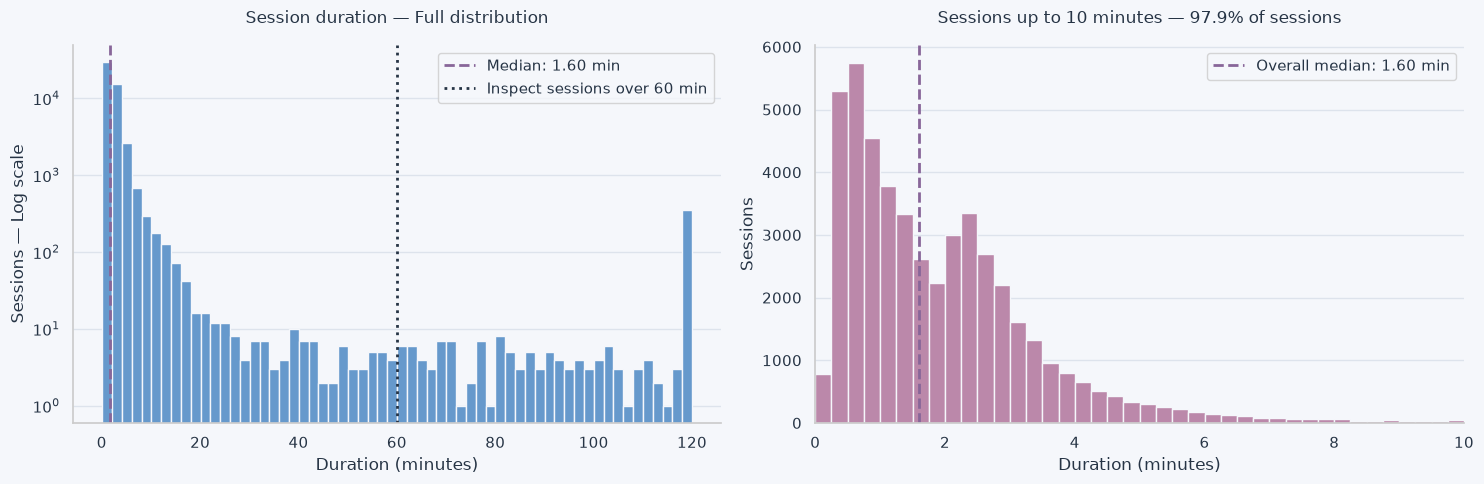

In [41]:
# show the full duration distribution and a detailed view up to 10 minutes
duration = sessions_work["session_duration_minutes"].dropna()
short_duration = duration.loc[duration.le(10)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    duration,
    bins=60,
    color=COLORS["blue"],
    edgecolor=COLORS["background"],
)

axes[0].axvline(
    duration.median(),
    color=COLORS["highlight"],
    linestyle="--",
    linewidth=2,
    label=f"Median: {duration.median():.2f} min",
)

axes[0].axvline(
    60,
    color=COLORS["text"],
    linestyle=":",
    linewidth=2,
    label="Inspect sessions over 60 min",
)

axes[0].set_title("Session duration — Full distribution", pad=16)
axes[0].set_xlabel("Duration (minutes)")
axes[0].set_ylabel("Sessions — Log scale")
axes[0].set_yscale("log")
axes[0].legend()

axes[1].hist(
    short_duration,
    bins=40,
    range=(0, 10),
    color=COLORS["lavender"],
    edgecolor=COLORS["background"],
)

axes[1].axvline(
    duration.median(),
    color=COLORS["highlight"],
    linestyle="--",
    linewidth=2,
    label=f"Overall median: {duration.median():.2f} min",
)

axes[1].set_title(
    f"Sessions up to 10 minutes — "
    f"{len(short_duration) / len(duration):.1%} of sessions",
    pad=16,
)

axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Sessions")
axes[1].set_xlim(0, 10)
axes[1].legend()

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

**Findings**

All sessions have complete timestamps and positive durations.
The median duration is 1.60 minutes, while the mean is 3.12 minutes.
The 95th percentile is 5.48 minutes.

A total of 464 sessions last longer than 60 minutes. The maximum
duration is approximately 120 minutes. These sessions require
further inspection and are retained for now.

**Auswertung**

Alle Sessions haben vollständige Zeitangaben und eine positive Dauer.
Der Median beträgt 1,60 Minuten, der Mittelwert 3,12 Minuten.
Das 95. Perzentil liegt bei 5,48 Minuten.

464 Sessions dauern länger als 60 Minuten. Die maximale Dauer beträgt
rund 120 Minuten. Diese Sessions werden zunächst beibehalten und
genauer untersucht.

### 4.3 Inspect long sessions
### Lange Sessions untersuchen

Inspect sessions lasting more than 60 minutes and compare their
duration with page clicks. A long duration alone does not indicate
a data error.

Sessions mit mehr als 60 Minuten untersuchen und ihre Dauer mit
den Seitenklicks vergleichen. Eine lange Dauer allein ist kein
Hinweis auf einen Datenfehler.

session_id,user_id,session_start,session_end,session_duration_minutes,page_clicks
171470-9d2d08615e2946d1a9b20308581701db,171470,09.03.2023 22:17:14,10.03.2023 00:17:14,120.00,200
171470-f7cf9854de5f4faa8f467b7ec2b1c03a,171470,10.07.2023 02:46:09,10.07.2023 04:46:09,120.00,200
174997-d37e4081489646fc891296f5e21b96f1,174997,05.01.2023 20:17:50,05.01.2023 22:17:50,120.00,155
204943-2e94ce7e5ca54986b68f78d4898483bc,204943,28.07.2023 12:51:08,28.07.2023 14:51:08,120.00,137
204997-c91e55e8e3804784ad998e48c48f10c7,204997,09.05.2023 20:25:06,09.05.2023 22:25:06,120.00,200
220725-78577d2fb05b4baba11a92867932ea3b,220725,01.03.2023 01:32:36,01.03.2023 03:32:36,120.00,136
229108-e221e546085f47c693398c7cc667cfc1,229108,08.05.2023 16:12:58,08.05.2023 18:12:58,120.00,200
306819-f482148662394e8fa28422e9cc844626,306819,27.01.2023 21:44:26,27.01.2023 23:44:26,120.00,156
313724-3f29d14059a54158ac083ad8ee350b5c,313724,01.07.2023 04:15:38,01.07.2023 06:15:38,120.00,123
328590-ae98faf93a274a28ae0b5ec8a7f9480e,328590,22.03.2023 19:32:49,22.03.2023 21:32:49,120.00,184


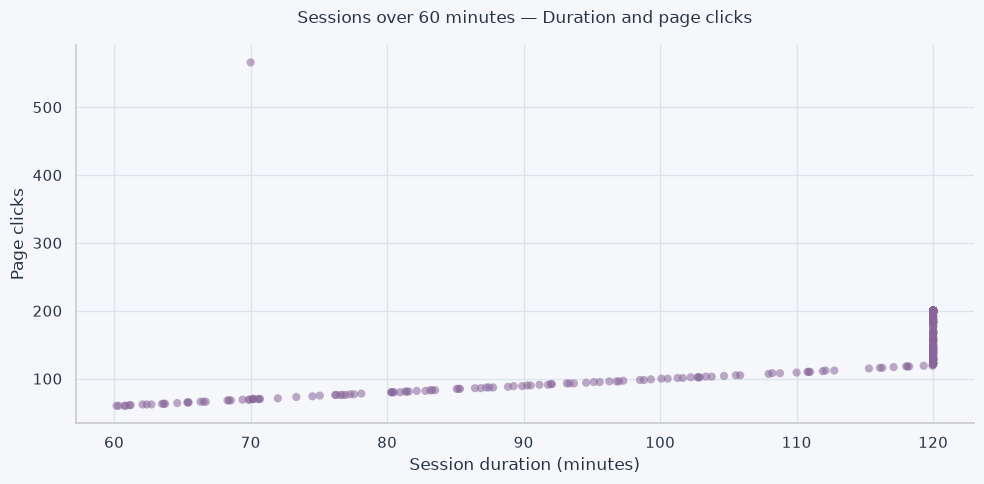

In [42]:
# inspect long sessions without removing or changing them
long_sessions = sessions_work.loc[
    sessions_work["session_duration_minutes"].gt(60)
].copy()

longest_sessions = (
    long_sessions.nlargest(15, "session_duration_minutes")
    [[
        "session_id",
        "user_id",
        "session_start",
        "session_end",
        "session_duration_minutes",
        "page_clicks",
    ]]
)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        longest_sessions,
        "Sessions — 15 longest sessions",
        {
            "session_start": "{:%d.%m.%Y %H:%M:%S}",
            "session_end": "{:%d.%m.%Y %H:%M:%S}",
            "session_duration_minutes": "{:.2f}",
            "page_clicks": "{:,.0f}",
        },
    ).to_html()
    + '</div>'
))

# compare duration and page clicks among long sessions
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    long_sessions["session_duration_minutes"],
    long_sessions["page_clicks"],
    color=COLORS["highlight"],
    alpha=0.55,
    s=35,
    edgecolors="none",
)

ax.set_title(
    "Sessions over 60 minutes — Duration and page clicks",
    pad=16,
)
ax.set_xlabel("Session duration (minutes)")
ax.set_ylabel("Page clicks")
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

In [43]:
# check repeated boundary values across all sessions
boundary_checks = pd.DataFrame({
    "check": [
        "Duration exactly 120 minutes",
        "Duration over 120 minutes",
        "Exactly 200 page clicks",
        "More than 200 page clicks",
        "120 minutes and 200 page clicks",
    ],
    "sessions": [
        int(sessions_work["session_duration_minutes"].eq(120).sum()),
        int(sessions_work["session_duration_minutes"].gt(120).sum()),
        int(sessions_work["page_clicks"].eq(200).sum()),
        int(sessions_work["page_clicks"].gt(200).sum()),
        int((
            sessions_work["session_duration_minutes"].eq(120)
            & sessions_work["page_clicks"].eq(200)
        ).sum()),
    ],
})

display(style_overview(
    boundary_checks,
    "Sessions — Repeated boundary values",
    {"sessions": "{:,.0f}"},
))

check,sessions
Duration exactly 120 minutes,345
Duration over 120 minutes,0
Exactly 200 page clicks,254
More than 200 page clicks,16
120 minutes and 200 page clicks,253


**Findings**

Of the 464 sessions lasting more than 60 minutes, 345 last exactly
120 minutes. No session exceeds this duration. This concentration
suggests a possible recording limit or a pattern in the generated
project data; the cause cannot be confirmed from the available fields.

Exactly 200 page clicks occur in 254 sessions, including 253 sessions
lasting exactly 120 minutes. However, 16 sessions exceed 200 clicks,
so this is not a universal click limit.

These sessions are retained. The concentration at 120 minutes should
be considered when interpreting session duration as an engagement metric.

**Auswertung**

Von den 464 Sessions über 60 Minuten dauern 345 exakt 120 Minuten.
Keine Session dauert länger. Diese Häufung deutet auf eine mögliche
Erfassungsgrenze oder ein Muster in den erzeugten Projektdaten hin.
Die Ursache lässt sich anhand der vorhandenen Felder nicht bestätigen.

254 Sessions enthalten exakt 200 Seitenklicks; 253 davon dauern
genau 120 Minuten. Da 16 Sessions mehr als 200 Klicks aufweisen,
handelt es sich nicht um eine allgemeine Klickobergrenze.

Die Sessions bleiben erhalten. Die Häufung bei 120 Minuten ist bei
der späteren Interpretation der Sessiondauer als Aktivitätsmerkmal
zu berücksichtigen.

### 4.4 Validate page clicks
### Seitenklicks prüfen

Check page clicks for missing, negative and non-integer values.
Inspect sessions with more than 200 clicks without automatically
classifying them as errors.

Seitenklicks auf fehlende, negative und nicht ganzzahlige Werte prüfen.
Sessions mit mehr als 200 Klicks untersuchen, ohne sie automatisch
als Fehler einzustufen.

In [44]:
# validate page clicks without changing the original values
clicks = pd.to_numeric(
    sessions_work["page_clicks"],
    errors="coerce",
)

click_checks = pd.DataFrame({
    "check": [
        "Missing source values",
        "Non-numeric values",
        "Negative values",
        "Non-integer values",
        "Zero page clicks",
        "More than 200 page clicks",
    ],
    "sessions": [
        int(sessions_work["page_clicks"].isna().sum()),
        int((
            sessions_work["page_clicks"].notna()
            & clicks.isna()
        ).sum()),
        int(clicks.lt(0).sum()),
        int((clicks.notna() & clicks.mod(1).ne(0)).sum()),
        int(clicks.eq(0).sum()),
        int(clicks.gt(200).sum()),
    ],
})

click_summary = pd.DataFrame({
    "metric": [
        "Minimum",
        "Median",
        "Mean",
        "95th percentile",
        "Maximum",
    ],
    "page_clicks": [
        clicks.min(),
        clicks.median(),
        clicks.mean(),
        clicks.quantile(0.95),
        clicks.max(),
    ],
})

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    + '<div>'
    + style_overview(
        click_checks,
        "Sessions — Page click checks",
        {"sessions": "{:,.0f}"},
    ).to_html()
    + '</div><div>'
    + style_overview(
        click_summary,
        "Sessions — Page click summary",
        {"page_clicks": "{:,.2f}"},
    ).to_html()
    + '</div></div>'
))

# inspect all sessions above the review threshold
high_click_sessions = sessions_work.loc[
    clicks.gt(200),
    [
        "session_id",
        "user_id",
        "session_duration_minutes",
        "page_clicks",
    ],
].sort_values("page_clicks", ascending=False)

display(HTML(
    '<div style="overflow-x:auto; margin-top:24px;">'
    + style_overview(
        high_click_sessions,
        "Sessions — More than 200 page clicks",
        {
            "session_duration_minutes": "{:.2f}",
            "page_clicks": "{:,.0f}",
        },
    ).to_html()
    + '</div>'
))

check,sessions
Missing source values,0
Non-numeric values,0
Negative values,0
Non-integer values,0
Zero page clicks,0
More than 200 page clicks,16
metric,page_clicks
Minimum,1.00
Median,13.00
Mean,17.59


session_id,user_id,session_duration_minutes,page_clicks
590420-814ccf31a57445a889176d909b2c2057,590420,70.00,566
478760-fe8c0bca3345472ba2fe168745c04388,478760,34.03,279
514300-a1cc57558ca74fc291b46a6f7aa59f84,514300,33.90,274
499780-0e658ccf562d4362a89b5fe311e7d16a,499780,32.22,262
602734-dd027e8dbab2430a803fed1caed3e510,602734,32.32,262
567651-98c3c9de6a6645938f437412aac2dd37,567651,32.22,261
558270-f48505641cbd44d39c70f817e0b5ddb9,558270,30.07,243
527944-1ea3d8a5b46a4b4ea74780c74fa63109,527944,29.43,237
619079-70721bc014c64bca8bc33ceeb92dd205,619079,27.97,228
524448-bc3f0c5a5db54223afba86517101d028,524448,27.38,222


In [45]:
# calculate average clicks per minute
sessions_work["clicks_per_min"] = (
    sessions_work["page_clicks"]
    / sessions_work["session_duration_minutes"].where(
        sessions_work["session_duration_minutes"].gt(0)
    )
)

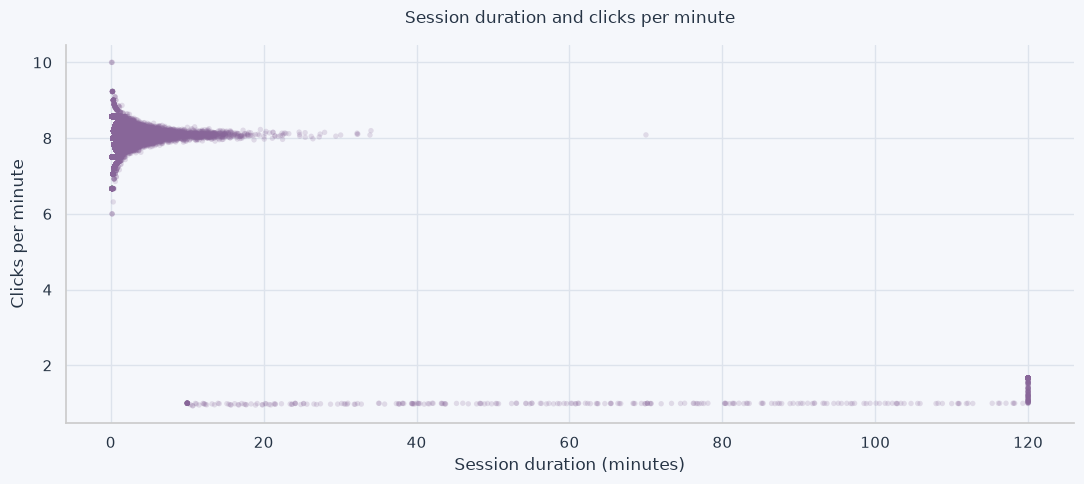

In [46]:
# compare session duration with average clicks per minute
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    sessions_work["session_duration_minutes"],
    sessions_work["clicks_per_min"],
    color=COLORS["highlight"],
    alpha=0.2,
    s=15,
    edgecolors="none",
)

ax.set_title("Session duration and clicks per minute", pad=16)
ax.set_xlabel("Session duration (minutes)")
ax.set_ylabel("Clicks per minute")
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

In [47]:
# temporarily separate the two visible click-rate bands
band_check = sessions_work.loc[
    sessions_work["clicks_per_min"].notna(),
    ["user_id", "clicks_per_min"],
].copy()

band_check["click_rate_band"] = np.where(
    band_check["clicks_per_min"] < 4,
    "Lower click rate",
    "Higher click rate",
)

# compare session counts and distinct users in each band
band_summary = (
    band_check.groupby("click_rate_band")
    .agg(
        sessions=("user_id", "size"),
        users=("user_id", "nunique"),
        median_clicks_per_min=("clicks_per_min", "median"),
    )
    .reset_index()
)

band_summary["session_share_pct"] = (
    band_summary["sessions"] / len(band_check) * 100
)

# determine whether users appear in one or both bands
user_bands = pd.crosstab(
    band_check["user_id"],
    band_check["click_rate_band"],
).reindex(
    columns=["Lower click rate", "Higher click rate"],
    fill_value=0,
)

has_lower = user_bands["Lower click rate"].gt(0)
has_higher = user_bands["Higher click rate"].gt(0)

user_pattern_summary = pd.DataFrame({
    "pattern": [
        "Lower click rate only",
        "Higher click rate only",
        "Both click-rate bands",
    ],
    "users": [
        int((has_lower & ~has_higher).sum()),
        int((has_higher & ~has_lower).sum()),
        int((has_lower & has_higher).sum()),
    ],
})

user_pattern_summary["share_pct"] = (
    user_pattern_summary["users"] / len(user_bands) * 100
)

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    '<div>'
    + style_overview(
        band_summary,
        "Click-rate bands — Sessions and users",
        {
            "sessions": "{:,.0f}",
            "users": "{:,.0f}",
            "median_clicks_per_min": "{:.2f}",
            "session_share_pct": "{:.2f}%",
        },
    ).to_html()
    + '</div><div>'
    + style_overview(
        user_pattern_summary,
        "Users — Appearance across click-rate bands",
        {
            "users": "{:,.0f}",
            "share_pct": "{:.2f}%",
        },
    ).to_html()
    + '</div></div>'
))

In [48]:
# compare duration and click-rate ranges within each band
pattern_details = sessions_work.loc[
    sessions_work["clicks_per_min"].notna(),
    ["session_duration_minutes", "page_clicks", "clicks_per_min"],
].copy()

pattern_details["click_rate_band"] = np.where(
    pattern_details["clicks_per_min"] < 4,
    "Lower click rate",
    "Higher click rate",
)

pattern_summary = (
    pattern_details.groupby("click_rate_band")
    .agg(
        min_duration=("session_duration_minutes", "min"),
        median_duration=("session_duration_minutes", "median"),
        max_duration=("session_duration_minutes", "max"),
        min_click_rate=("clicks_per_min", "min"),
        max_click_rate=("clicks_per_min", "max"),
    )
    .reset_index()
)

display(style_overview(
    pattern_summary,
    "Session patterns — Duration and click-rate ranges",
    {
        "min_duration": "{:.2f}",
        "median_duration": "{:.2f}",
        "max_duration": "{:.2f}",
        "min_click_rate": "{:.2f}",
        "max_click_rate": "{:.2f}",
    },
))

click_rate_band,min_duration,median_duration,max_duration,min_click_rate,max_click_rate
Higher click rate,0.10,1.57,70.00,6.00,10.00
Lower click rate,10.00,120.00,120.00,0.93,1.67


**Findings**

Sessions with a high click rate account for 48,601 sessions (98.76%).
They show 6–10 clicks per minute and a median duration of 1.57 minutes.

Sessions with a low click rate account for 610 sessions (1.24%).
They show approximately 0.93–1.67 clicks per minute and a median
duration of 120 minutes. No sessions fall between these click-rate ranges.

The two session patterns cannot each be assigned to a separate user group.
However, users differ in whether they have only high-click-rate sessions
or also low-click-rate sessions. Whether this distinction supports
meaningful behavioral groups remains to be investigated.

The regular patterns and concentration at 120 minutes may reflect
technical or data-generation effects.

**Auswertung**

Sessions mit hoher Klickrate machen 48.601 Sessions (98,76 %) aus.
Sie weisen 6–10 Klicks pro Minute und eine mediane Dauer von
1,57 Minuten auf.

Sessions mit niedriger Klickrate machen 610 Sessions (1,24 %) aus.
Sie weisen etwa 0,93–1,67 Klicks pro Minute und eine mediane Dauer
von 120 Minuten auf. Zwischen diesen Klickratenbereichen liegen
keine Sessions.

Die beiden Sessionmuster lassen sich nicht jeweils einer eigenständigen
Nutzergruppe zuordnen. Allerdings unterscheiden sich Nutzer darin, ob sie
ausschließlich Sessions mit hoher Klickrate oder zusätzlich Sessions mit
niedriger Klickrate aufweisen. Ob daraus sinnvolle Verhaltensgruppen
entstehen, bleibt zu untersuchen.

Die regelmäßigen Muster und die Häufung bei 120 Minuten könnten
technische oder erzeugungsbedingte Ursachen haben. 

### 4.5 Validate discount indicators and amounts
### Rabattkennzeichnungen und Rabatthöhen prüfen

Compare flight and hotel discount indicators with their corresponding
amounts. Distinguish expected missing amounts when no discount is
indicated from missing amounts despite a discount indicator.

Die Rabattkennzeichnungen für Flüge und Hotels mit den zugehörigen
Rabatthöhen vergleichen. Fehlende Beträge ohne Rabattkennzeichnung
von fehlenden Beträgen trotz Rabattkennzeichnung unterscheiden.

In [49]:
# inspect discount indicators and amounts without changing values
discount_tables = []

for booking_type in ["flight", "hotel"]:
    flag = sessions_work[f"{booking_type}_discount"]
    source = sessions_work[f"{booking_type}_discount_amount"]
    amount = pd.to_numeric(source, errors="coerce")

    flag_true = flag.eq(True).fillna(False)
    flag_false = flag.eq(False).fillna(False)

    checks = pd.DataFrame({
        "check": [
            "Missing discount indicator",
            "Invalid non-missing indicator",
            "No discount — Missing amount",
            "No discount — Amount present",
            "Discount — Missing amount",
            "Discount — Amount present",
            "Non-numeric amount",
            "Negative amount",
            "Zero amount",
        ],
        "sessions": [
            int(flag.isna().sum()),
            int((flag.notna() & ~flag.isin([True, False])).sum()),
            int((flag_false & source.isna()).sum()),
            int((flag_false & source.notna()).sum()),
            int((flag_true & source.isna()).sum()),
            int((flag_true & source.notna()).sum()),
            int((source.notna() & amount.isna()).sum()),
            int(amount.lt(0).sum()),
            int(amount.eq(0).sum()),
        ],
    })

    discount_tables.append(
        '<div>'
        + style_overview(
            checks,
            f"{booking_type.title()} discounts — Consistency checks",
            {"sessions": "{:,.0f}"},
        ).to_html()
        + '</div>'
    )

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    + "".join(discount_tables)
    + '</div>'
))

check,sessions
Missing discount indicator,0
Invalid non-missing indicator,0
No discount — Missing amount,"40,319"
No discount — Amount present,0
Discount — Missing amount,610
Discount — Amount present,"8,282"
Non-numeric amount,0
Negative amount,0
Zero amount,0
check,sessions


In [50]:
# compare missing discount amounts with the low-click-rate pattern
flight_missing = (
    sessions_work["flight_discount"].eq(True)
    & sessions_work["flight_discount_amount"].isna()
).fillna(False)

hotel_missing = (
    sessions_work["hotel_discount"].eq(True)
    & sessions_work["hotel_discount_amount"].isna()
).fillna(False)

low_click_rate = sessions_work["clicks_per_min"].lt(4).fillna(False)

overlap_checks = pd.DataFrame({
    "check": [
        "Flight discount — Missing amount",
        "Hotel discount — Missing amount",
        "Both discount amounts missing despite indicators",
        "Sessions with low click rate",
        "Low click rate and both amounts missing",
        "Different membership — Flight vs. hotel",
        "Different membership — Both missing vs. low click rate",
    ],
    "sessions": [
        int(flight_missing.sum()),
        int(hotel_missing.sum()),
        int((flight_missing & hotel_missing).sum()),
        int(low_click_rate.sum()),
        int((low_click_rate & flight_missing & hotel_missing).sum()),
        int((flight_missing ^ hotel_missing).sum()),
        int(((flight_missing & hotel_missing) ^ low_click_rate).sum()),
    ],
})

display(style_overview(
    overlap_checks,
    "Sessions — Discount gaps and click-rate overlap",
    {"sessions": "{:,.0f}"},
))

check,sessions
Flight discount — Missing amount,610
Hotel discount — Missing amount,610
Both discount amounts missing despite indicators,610
Sessions with low click rate,610
Low click rate and both amounts missing,610
Different membership — Flight vs. hotel,0
Different membership — Both missing vs. low click rate,0


**Findings and next step**

The same 610 sessions combine a low click rate with flight and hotel
discount indicators set to True, while both discount amounts are missing.
Outside these sessions, all indicated discounts have an amount recorded.

The cause remains unclear. These sessions are retained, and missing
discount amounts are not replaced.

Next, validate their booking and cancellation indicators and examine
whether these reveal further shared characteristics.

**Auswertung und nächster Schritt**

Dieselben 610 Sessions weisen eine niedrige Klickrate sowie Flug- und
Hotelrabattkennzeichnungen mit True auf, während beide Rabatthöhen fehlen.
Außerhalb dieser Sessions ist bei jeder Rabattkennzeichnung eine Höhe vorhanden.

Die Ursache bleibt offen. Die Sessions bleiben erhalten; fehlende
Rabatthöhen werden nicht ersetzt.

Als Nächstes die Buchungs- und Stornierungskennzeichnungen prüfen und
untersuchen, ob sich weitere gemeinsame Merkmale zeigen.

### 4.6 Booking and cancellation indicators in the unusual sessions
### Buchungs- und Stornierungskennzeichnungen der auffälligen Sessions

Validate the booking and cancellation indicators, then compare the
610 sessions identified above with the remaining sessions.
This check uses session records only, without verifying booking details.

Die Buchungs- und Stornierungskennzeichnungen prüfen. Anschließend die
610 zuvor identifizierten Sessions mit den übrigen Sessions vergleichen.
Die Prüfung verwendet ausschließlich Sessiondaten; Buchungsdetails
werden hier noch nicht bestätigt.

In [51]:
# validate booking and cancellation indicators
indicator_columns = [
    "flight_booked",
    "hotel_booked",
    "cancellation",
]

indicator_checks = pd.DataFrame([
    {
        "column": column,
        "missing": int(sessions_work[column].isna().sum()),
        "invalid": int((
            sessions_work[column].notna()
            & ~sessions_work[column].isin([True, False])
        ).sum()),
    }
    for column in indicator_columns
])

display(style_overview(
    indicator_checks,
    "Sessions — Booking and cancellation indicator checks",
    {
        "missing": "{:,.0f}",
        "invalid": "{:,.0f}",
    },
))

if indicator_checks[["missing", "invalid"]].to_numpy().sum() > 0:
    raise ValueError("Review indicator values before comparing groups.")

# identify the previously observed discount-gap pattern
unusual_mask = (
    sessions_work["flight_discount"].eq(True)
    & sessions_work["flight_discount_amount"].isna()
    & sessions_work["hotel_discount"].eq(True)
    & sessions_work["hotel_discount_amount"].isna()
).fillna(False)

# summarize recorded indicators within each session group
activity_rows = []

for group_name, group_mask in [
    ("Unusual sessions", unusual_mask),
    ("Other sessions", ~unusual_mask),
]:
    group = sessions_work.loc[group_mask]

    activity_masks = {
        "Flight booking flag": group["flight_booked"].eq(True),
        "Hotel booking flag": group["hotel_booked"].eq(True),
        "Both booking flags": (
            group["flight_booked"].eq(True)
            & group["hotel_booked"].eq(True)
        ),
        "Neither booking flag": (
            group["flight_booked"].eq(False)
            & group["hotel_booked"].eq(False)
        ),
        "Cancellation flag": group["cancellation"].eq(True),
    }

    for activity, mask in activity_masks.items():
        activity_rows.append({
            "group": group_name,
            "activity": activity,
            "sessions": int(mask.sum()),
            "share_pct": (
                mask.sum() / len(group) * 100
                if len(group) else float("nan")
            ),
        })

activity_summary = pd.DataFrame(activity_rows)

# display the two groups side by side
table_html = []

for group_name in ["Unusual sessions", "Other sessions"]:
    group_summary = activity_summary.loc[
        activity_summary["group"].eq(group_name),
        ["activity", "sessions", "share_pct"],
    ]

    group_size = (
        int(unusual_mask.sum())
        if group_name == "Unusual sessions"
        else int((~unusual_mask).sum())
    )

    table_html.append(
        "<div>"
        + style_overview(
            group_summary,
            f"{group_name} — Total sessions: {group_size:,}",
            {
                "sessions": "{:,.0f}",
                "share_pct": "{:.2f}%",
            },
        ).to_html()
        + "</div>"
    )

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    + "".join(table_html)
    + "</div>"
))

column,missing,invalid
flight_booked,0,0
hotel_booked,0,0
cancellation,0,0


activity,sessions,share_pct
Flight booking flag,610,100.00%
Hotel booking flag,610,100.00%
Both booking flags,610,100.00%
Neither booking flag,0,0.00%
Cancellation flag,610,100.00%
activity,sessions,share_pct
Flight booking flag,"13,710",28.21%
Hotel booking flag,"14,309",29.44%
Both booking flags,"11,927",24.54%
Neither booking flag,"32,509",66.89%


**Findings**

All 610 previously identified unusual sessions are marked as cancellations.
No other session carries a cancellation flag. Every cancellation session
also has both flight and hotel booking indicators set to True.

The low-click-rate pattern therefore corresponds exactly to sessions
marked as cancellations. It should not be interpreted as evidence of
indecisive browsing behavior.

Missing discount amounts in these sessions may reflect how cancellation
records are represented. This explanation remains unconfirmed.
No values are changed or removed.

**Auswertung**

Alle 610 zuvor identifizierten auffälligen Sessions sind als Stornierung
gekennzeichnet. Keine andere Session trägt diese Kennzeichnung.
Bei sämtlichen Stornierungssessions stehen außerdem beide
Buchungskennzeichnungen auf True.

Das Muster niedriger Klickrate entspricht somit exakt den als Stornierung
gekennzeichneten Sessions. Es ist kein Beleg für unentschlossenes Suchverhalten.

Die fehlenden Rabatthöhen könnten mit der Darstellung von
Stornierungsdatensätzen zusammenhängen. Diese Erklärung ist noch
nicht bestätigt. Es werden keine Werte verändert oder entfernt.

### 4.7 Link cancellation sessions to earlier sessions
### Stornierungssessions früheren Sessions zuordnen

Use trip IDs to link cancellation sessions to other sessions.
Check whether an earlier session exists for the same user and trip
and whether it contains a flight or hotel booking indicator.

Stornierungssessions anhand der Reise-ID mit weiteren Sessions verknüpfen.
Prüfen, ob für denselben Nutzer und dieselbe Reise eine frühere Session
mit einer Flug- oder Hotelbuchungskennzeichnung vorhanden ist.

In [52]:
# identify cancellation sessions and usable trip IDs
cancel_mask = sessions_work["cancellation"].eq(True)

trip_present = (
    sessions_work["trip_id"]
    .astype("string")
    .str.strip()
    .fillna("")
    .ne("")
)

cancellations = sessions_work.loc[
    cancel_mask & trip_present,
    ["session_id", "user_id", "trip_id", "session_start"],
].copy()

other_sessions = sessions_work.loc[
    ~cancel_mask & trip_present,
    [
        "session_id",
        "user_id",
        "trip_id",
        "session_start",
        "flight_booked",
        "hotel_booked",
    ],
].copy()

# link on trip ID, then verify user identity and chronological order
linked_sessions = cancellations.merge(
    other_sessions,
    on="trip_id",
    how="left",
    suffixes=("_cancel", "_earlier"),
)

linked_sessions["same_user"] = (
    linked_sessions["user_id_cancel"]
    .eq(linked_sessions["user_id_earlier"])
    .fillna(False)
)

linked_sessions["earlier_session"] = (
    linked_sessions["session_start_earlier"]
    .lt(linked_sessions["session_start_cancel"])
    .fillna(False)
)

linked_sessions["booking_flag_present"] = (
    linked_sessions["flight_booked"].eq(True)
    | linked_sessions["hotel_booked"].eq(True)
).fillna(False)

linked_sessions["valid_earlier_booking"] = (
    linked_sessions["same_user"]
    & linked_sessions["earlier_session"]
    & linked_sessions["booking_flag_present"]
)

# count cancellation sessions, not merged rows
matched_trip_ids = set(
    linked_sessions.loc[
        linked_sessions["session_id_earlier"].notna(),
        "session_id_cancel",
    ]
)

same_user_ids = set(
    linked_sessions.loc[
        linked_sessions["same_user"],
        "session_id_cancel",
    ]
)

earlier_booking_ids = set(
    linked_sessions.loc[
        linked_sessions["valid_earlier_booking"],
        "session_id_cancel",
    ]
)

link_checks = pd.DataFrame({
    "check": [
        "Total cancellation sessions",
        "Cancellation sessions without trip ID",
        "With another non-cancellation session for the trip",
        "With a non-cancellation session for the same user and trip",
        "With an earlier booking-flag session for the same user and trip",
        "Without a matching earlier booking-flag session",
    ],
    "sessions": [
        int(cancel_mask.sum()),
        int((cancel_mask & ~trip_present).sum()),
        len(matched_trip_ids),
        len(same_user_ids),
        len(earlier_booking_ids),
        int(cancel_mask.sum()) - len(earlier_booking_ids),
    ],
})

display(style_overview(
    link_checks,
    "Cancellations — Links to earlier sessions",
    {"sessions": "{:,.0f}"},
))

# summarize which booking indicators the earlier sessions contain
earlier_bookings = linked_sessions.loc[
    linked_sessions["valid_earlier_booking"]
].copy()

earlier_bookings["booking_type"] = np.select(
    [
        earlier_bookings["flight_booked"].eq(True)
        & earlier_bookings["hotel_booked"].eq(True),
        earlier_bookings["flight_booked"].eq(True),
        earlier_bookings["hotel_booked"].eq(True),
    ],
    [
        "Flight and hotel",
        "Flight only",
        "Hotel only",
    ],
    default="Neither",
)

booking_type_summary = (
    earlier_bookings.groupby("booking_type")
    ["session_id_cancel"]
    .nunique()
    .reset_index(name="cancellation_sessions")
)

display(style_overview(
    booking_type_summary,
    "Earlier sessions — Recorded booking types",
    {"cancellation_sessions": "{:,.0f}"},
))

check,sessions
Total cancellation sessions,610
Cancellation sessions without trip ID,0
With another non-cancellation session for the trip,603
With a non-cancellation session for the same user and trip,603
With an earlier booking-flag session for the same user and trip,603
Without a matching earlier booking-flag session,7


booking_type,cancellation_sessions
Flight and hotel,363
Flight only,190
Hotel only,50


**Findings**

Of 610 cancellation sessions, 603 can be linked to an earlier session
for the same user and trip containing a booking indicator.

The earlier sessions indicate flight and hotel bookings in 363 cases,
flight only in 190 cases and hotel only in 50 cases. All cancellation
sessions nevertheless have both booking indicators set to True.
These indicators must therefore not be counted as new combined
bookings in cancellation sessions.

Seven cancellation sessions have no matching earlier booking session
in the current export. Their booking history requires further checking;
the missing match alone does not establish a data error.

**Auswertung**

Von 610 Stornierungssessions lassen sich 603 einer früheren Session
desselben Nutzers und derselben Reise mit Buchungskennzeichnung zuordnen.

Die früheren Sessions kennzeichnen in 363 Fällen Flug und Hotel,
in 190 Fällen nur einen Flug und in 50 Fällen nur ein Hotel.
Trotzdem stehen bei sämtlichen Stornierungssessions beide
Buchungsindikatoren auf True. Diese Kennzeichnungen dürfen deshalb
nicht als neue kombinierte Buchungen gezählt werden.

Für sieben Stornierungssessions fehlt im aktuellen Export eine passende
frühere Buchungssession. Ihre Buchungshistorie muss weiter geprüft werden.
Die fehlende Zuordnung allein belegt keinen Datenfehler.

In [53]:
# inspect cancellations without a matching earlier booking session
unmatched_cancellations = sessions_work.loc[
    sessions_work["cancellation"].eq(True)
    & ~sessions_work["session_id"].isin(earlier_booking_ids),
    [
        "session_id",
        "user_id",
        "trip_id",
        "session_start",
        "flight_booked",
        "hotel_booked",
    ],
].sort_values("session_start")

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        unmatched_cancellations,
        "Cancellations — Cases without an earlier booking match",
        {"session_start": "{:%d.%m.%Y %H:%M:%S}"},
    ).to_html()
    + '</div>'
))

# generate a read-only SQL query to search the full session history
trip_ids = unmatched_cancellations["trip_id"].dropna().unique()

if len(trip_ids):
    sql_trip_ids = ",\n    ".join(
        "'" + str(trip_id).replace("'", "''") + "'"
        for trip_id in trip_ids
    )

    history_query = (
        "select\n"
        "    session_id,\n"
        "    user_id,\n"
        "    trip_id,\n"
        "    session_start,\n"
        "    session_end,\n"
        "    flight_booked,\n"
        "    hotel_booked,\n"
        "    cancellation\n"
        "from sessions\n"
        "where trip_id in (\n"
        f"    {sql_trip_ids}\n"
        ")\n"
        "order by trip_id, session_start;"
    )

    print("Run this query in Beekeeper:\n")
    print(history_query)

session_id,user_id,trip_id,session_start,flight_booked,hotel_booked
498500-4f54c05abc824775937b6a61b322f400,498500,498500-8625a588e269412d9c6ac9ddbbb19a9d,04.01.2023 13:50:00,True,True
204997-021a10d531b0433a89496a7ecfa4a965,204997,204997-303a3759d5814673b7c60db793d46cdd,05.01.2023 09:11:24,True,True
182191-59dc638b9f5f46a3be89d8688a28432e,182191,182191-de32473e56244ac3bed8490f76398b2f,05.01.2023 14:26:34,True,True
174997-d37e4081489646fc891296f5e21b96f1,174997,174997-a7c3a96620594e849a2345ac4e0bd45d,05.01.2023 20:17:50,True,True
468409-78c0b06b3dca4321b8b5deffa42dad86,468409,468409-a54d1d56a17e44448932f672f63305f9,08.01.2023 17:18:05,True,True
508111-770195c941ad4c57808fe5bd652af8fa,508111,508111-0a8cf6c22c6149f2970a8c18a470c4cb,15.01.2023 19:58:58,True,True
171470-9d2d08615e2946d1a9b20308581701db,171470,171470-3c9552d5b3b0401e82cb943b28eef629,09.03.2023 22:17:14,True,True


Run this query in Beekeeper:

select
    session_id,
    user_id,
    trip_id,
    session_start,
    session_end,
    flight_booked,
    hotel_booked,
    cancellation
from sessions
where trip_id in (
    '498500-8625a588e269412d9c6ac9ddbbb19a9d',
    '204997-303a3759d5814673b7c60db793d46cdd',
    '182191-de32473e56244ac3bed8490f76398b2f',
    '174997-a7c3a96620594e849a2345ac4e0bd45d',
    '468409-a54d1d56a17e44448932f672f63305f9',
    '508111-0a8cf6c22c6149f2970a8c18a470c4cb',
    '171470-3c9552d5b3b0401e82cb943b28eef629'
)
order by trip_id, session_start;


**Findings — Follow-up database check**

The full database contains an earlier booking session for each of the
seven cancellation sessions without a local match. All seven earlier
sessions occurred before 4 January 2023 and therefore fall outside
the local session export.

All 610 cancellation sessions can consequently be linked to an earlier
booking session: 603 within the export and seven through the additional
database check. The seven missing local matches reflect the export's
time boundary, not missing booking records in the database.

For trip-level analyses, booking and cancellation sessions must be
linked by trip ID, even when they fall in different time periods.

**Auswertung — Ergänzende Datenbankprüfung**

Für alle sieben Stornierungssessions ohne lokale Zuordnung enthält
die vollständige Datenbank eine frühere Buchungssession. Diese liegt
jeweils vor dem 04.01.2023 und damit außerhalb des lokalen Sessionexports.

Somit lassen sich alle 610 Stornierungssessions einer früheren
Buchungssession zuordnen: 603 innerhalb des Exports und sieben durch
die ergänzende Datenbankprüfung. Die sieben zunächst fehlenden
Zuordnungen entstehen durch die zeitliche Exportgrenze, nicht durch
fehlende Buchungsdatensätze in der Datenbank.

Für reisebezogene Analysen müssen Buchungs- und Stornierungssessions
über die Reise-ID verknüpft werden, auch über Zeitraumgrenzen hinweg.

### 4.8 Inspect discount amounts
### Rabatthöhen untersuchen

Inspect the range and distribution of recorded flight and hotel
discount amounts. Check whether values are consistent with a fractional
discount scale from 0 to 1. Missing values are excluded from these
summaries and remain unchanged.

Wertebereich und Verteilung der vorhandenen Flug- und Hotelrabatte
untersuchen. Prüfen, ob die Werte mit einer anteiligen Rabattskala
von 0 bis 1 vereinbar sind. Fehlende Werte werden in diesen Auswertungen
nicht berücksichtigt und bleiben unverändert.

metric,value
Sessions with recorded discount,"8,282"
Number of different discount rates,12
Smallest discount,5%
Median discount,10%
Average discount,14%
Largest discount,60%
Discounts below 0%,0
Discounts above 100%,0
metric,value
Sessions with recorded discount,"6,205"


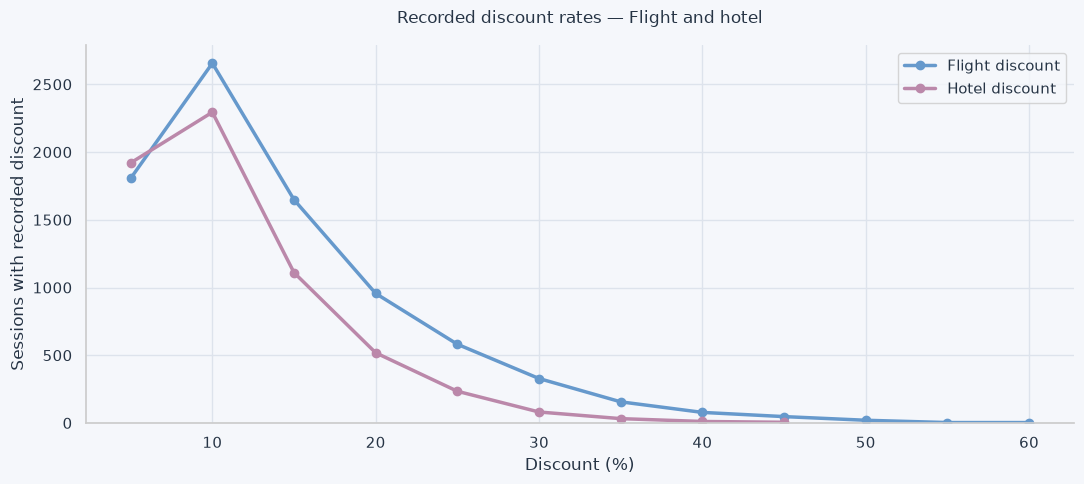

In [54]:
# summarize discount rates and prepare their frequencies
discount_tables = []
discount_frequencies = {}

for booking_type in ["flight", "hotel"]:
    amount = pd.to_numeric(
        sessions_work[f"{booking_type}_discount_amount"],
        errors="coerce",
    ).dropna()

    discount_pct = amount.mul(100).round(8)

    summary = pd.DataFrame({
        "metric": [
            "Sessions with recorded discount",
            "Number of different discount rates",
            "Smallest discount",
            "Median discount",
            "Average discount",
            "Largest discount",
            "Discounts below 0%",
            "Discounts above 100%",
        ],
        "value": [
            f"{len(amount):,}",
            f"{discount_pct.nunique():,}",
            f"{discount_pct.min():.0f}%",
            f"{discount_pct.median():.0f}%",
            f"{discount_pct.mean():.0f}%",
            f"{discount_pct.max():.0f}%",
            f"{int(amount.lt(0).sum()):,}",
            f"{int(amount.gt(1).sum()):,}",
        ],
    })

    discount_tables.append(
        "<div>"
        + style_overview(
            summary,
            f"{booking_type.title()} discounts — Overview",
        ).to_html()
        + "</div>"
    )

    discount_frequencies[booking_type] = (
        discount_pct.value_counts().sort_index()
    )

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    + "".join(discount_tables)
    + "</div>"
))

# compare frequencies at the recorded discount rates
fig, ax = plt.subplots(figsize=(11, 5))

for booking_type, color in [
    ("flight", COLORS["blue"]),
    ("hotel", COLORS["lavender"]),
]:
    frequency = discount_frequencies[booking_type]

    ax.plot(
        frequency.index,
        frequency.to_numpy(),
        label=f"{booking_type.title()} discount",
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=6,
    )

ax.set_title("Recorded discount rates — Flight and hotel", pad=16)
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Sessions with recorded discount")
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.legend()

fig.tight_layout()
plt.show()

**Findings**

Flight discount amounts are recorded in 8,282 sessions, with 12 different
rates ranging from 5% to 60%. Hotel discount amounts are recorded in
6,205 sessions, with nine rates ranging from 5% to 45%.

For both categories, 10% is the most frequent discount and the median.
Average discounts are approximately 14% for flights and 11% for hotels.
Larger discounts occur less frequently.

All recorded amounts are positive and below 100%. No correction is
indicated by these checks. These figures describe recorded discounts,
not whether they were redeemed or caused a booking.

**Auswertung**

Flugrabatte sind in 8.282 Sessions mit zwölf unterschiedlichen
Rabattsätzen zwischen 5 % und 60 % eingetragen. Hotelrabatte liegen
in 6.205 Sessions mit neun Rabattsätzen zwischen 5 % und 45 % vor.

Bei beiden Kategorien ist 10 % der häufigste Rabatt und zugleich
der Median. Die durchschnittlichen Rabatte betragen gerundet
14 % für Flüge und 11 % für Hotels. Höhere Rabatte treten seltener auf.

Alle vorhandenen Rabatthöhen sind positiv und liegen unter 100 %.
Aus diesen Prüfungen ergibt sich kein Korrekturbedarf. Die Zahlen
beschreiben verzeichnete Rabatte, nicht deren Einlösung oder
ihren Einfluss auf eine Buchung.

### 4.9 Validate session IDs and relationships
### Session-IDs und Verknüpfungen prüfen

Check session ID uniqueness, user references and trip IDs for sessions
with booking or cancellation indicators. Missing trip IDs in browsing
sessions are reported separately and are not automatically errors.

Eindeutige Session-IDs, Nutzerzuordnungen und Reise-IDs bei Sessions
mit Buchungs- oder Stornierungskennzeichnungen prüfen. Fehlende
Reise-IDs bei reinen Suchsessions werden separat ausgewiesen und
nicht automatisch als Fehler betrachtet.

In [55]:
# identify missing IDs, including blank text values
def missing_id(series):
    return (
        series.astype("string")
        .str.strip()
        .fillna("")
        .eq("")
    )


missing_session = missing_id(sessions_work["session_id"])
missing_user = missing_id(sessions_work["user_id"])
missing_trip = missing_id(sessions_work["trip_id"])

booking_flag = (
    sessions_work["flight_booked"].eq(True)
    | sessions_work["hotel_booked"].eq(True)
)

cancellation_flag = sessions_work["cancellation"].eq(True)

# validate primary keys and references to the cleaned user table
id_checks = pd.DataFrame({
    "check": [
        "Missing session ID",
        "Duplicate session IDs — Additional rows",
        "Missing user ID",
        "User ID absent from cleaned users",
        "Booking flag without trip ID",
        "Cancellation flag without trip ID",
    ],
    "sessions": [
        int(missing_session.sum()),
        int(
            sessions_work.loc[
                ~missing_session, "session_id"
            ].duplicated().sum()
        ),
        int(missing_user.sum()),
        int((
            ~missing_user
            & ~sessions_work["user_id"].isin(users_work["user_id"])
        ).sum()),
        int((booking_flag & missing_trip).sum()),
        int((cancellation_flag & missing_trip).sum()),
    ],
})

# describe trip ID usage without treating repeated trips as duplicates
trip_user_counts = (
    sessions_work.loc[~missing_trip]
    .groupby("trip_id")["user_id"]
    .nunique()
)

trip_session_counts = (
    sessions_work.loc[~missing_trip]
    .groupby("trip_id")
    .size()
)

trip_summary = pd.DataFrame({
    "metric": [
        "Sessions without trip ID",
        "No booking or cancellation flag — No trip ID",
        "No booking or cancellation flag — Trip ID present",
        "Distinct trip IDs",
        "Trip IDs appearing in multiple sessions",
        "Trip IDs assigned to multiple users",
        "Maximum sessions per trip",
    ],
    "count": [
        int(missing_trip.sum()),
        int((~booking_flag & ~cancellation_flag & missing_trip).sum()),
        int((~booking_flag & ~cancellation_flag & ~missing_trip).sum()),
        len(trip_session_counts),
        int(trip_session_counts.gt(1).sum()),
        int(trip_user_counts.gt(1).sum()),
        int(trip_session_counts.max()) if len(trip_session_counts) else 0,
    ],
})

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    '<div>'
    + style_overview(
        id_checks,
        "Sessions — ID and relationship checks",
        {"sessions": "{:,.0f}"},
    ).to_html()
    + '</div><div>'
    + style_overview(
        trip_summary,
        "Sessions — Trip ID usage",
        {"count": "{:,.0f}"},
    ).to_html()
    + '</div></div>'
))

check,sessions
Missing session ID,0
Duplicate session IDs — Additional rows,0
Missing user ID,0
User ID absent from cleaned users,0
Booking flag without trip ID,0
Cancellation flag without trip ID,0
metric,count
Sessions without trip ID,"32,509"
No booking or cancellation flag — No trip ID,"32,509"
No booking or cancellation flag — Trip ID present,0


**Findings**

Session IDs are complete and unique. All sessions reference users
in the cleaned user table. Every session with a booking or cancellation
indicator has a trip ID.

The 32,509 sessions without a trip ID have neither a booking nor a
cancellation indicator. This is consistent with browsing sessions.

There are 16,099 distinct trip IDs. Of these, 603 occur twice,
consistent with the previously identified booking–cancellation pairs.
No trip ID is assigned to multiple users. No correction is required
based on these checks.

**Auswertung**

Alle Session-IDs sind vorhanden und eindeutig. Sämtliche Sessions
verweisen auf Nutzer der bereinigten Nutzertabelle. Jede Session
mit Buchungs- oder Stornierungskennzeichnung hat eine Reise-ID.

Die 32.509 Sessions ohne Reise-ID haben weder eine Buchungs- noch
eine Stornierungskennzeichnung. Das ist mit reinen Suchsessions vereinbar.

Es gibt 16.099 unterschiedliche Reise-IDs. Davon kommen 603 zweimal vor,
passend zu den zuvor ermittelten Buchungs-Stornierungs-Paaren.
Keine Reise-ID ist mehreren Nutzern zugeordnet. Aus diesen Prüfungen
ergibt sich kein Korrekturbedarf.

### 4.10 Validate session timing
### Zeitliche Konsistenz der Sessions prüfen

Check whether sessions occur before the user's sign-up date.
Identify sessions that start before an earlier session of the same
user has ended. Overlaps are reported for review, not automatically
classified as errors.

Prüfen, ob Sessions vor dem Anmeldedatum des Nutzers liegen.
Sessions erkennen, die beginnen, bevor eine frühere Session desselben
Nutzers beendet ist. Überschneidungen werden zur Prüfung ausgewiesen
und nicht automatisch als Fehler eingestuft.

In [56]:
# attach validated sign-up dates without changing sessions_work
timing_check = sessions_work[
    ["session_id", "user_id", "session_start", "session_end"]
].merge(
    users_work[["user_id", "sign_up_date"]],
    on="user_id",
    how="left",
    validate="many_to_one",
)

before_signup = (
    timing_check["session_start"].dt.normalize()
    < timing_check["sign_up_date"].dt.normalize()
)

# compare each start with the latest end of all preceding sessions
timing_check = timing_check.sort_values(
    ["user_id", "session_start", "session_end", "session_id"]
).copy()

timing_check["latest_end_so_far"] = (
    timing_check.groupby("user_id")["session_end"].cummax()
)

timing_check["latest_prior_end"] = (
    timing_check.groupby("user_id")["latest_end_so_far"].shift()
)

overlap = (
    timing_check["session_start"]
    < timing_check["latest_prior_end"]
).fillna(False)

timing_summary = pd.DataFrame({
    "check": [
        "Missing sign-up date after user matching",
        "Sessions on a date before sign-up",
        "Sessions starting before an earlier session ends",
        "Users with overlapping sessions",
    ],
    "count": [
        int(timing_check["sign_up_date"].isna().sum()),
        int(before_signup.sum()),
        int(overlap.sum()),
        int(timing_check.loc[overlap, "user_id"].nunique()),
    ],
})

display(style_overview(
    timing_summary,
    "Sessions — Timing checks",
    {"count": "{:,.0f}"},
))

# show overlapping sessions only when present
if overlap.any():
    overlap_preview = timing_check.loc[
        overlap,
        [
            "session_id",
            "user_id",
            "session_start",
            "session_end",
            "latest_prior_end",
        ],
    ].head(15)

    display(HTML(
        '<div style="overflow-x:auto; margin-top:24px;">'
        + style_overview(
            overlap_preview,
            "Sessions — Overlap preview, first 15 cases",
            {
                "session_start": "{:%d.%m.%Y %H:%M:%S}",
                "session_end": "{:%d.%m.%Y %H:%M:%S}",
                "latest_prior_end": "{:%d.%m.%Y %H:%M:%S}",
            },
        ).to_html()
        + '</div>'
    ))

check,count
Missing sign-up date after user matching,0
Sessions on a date before sign-up,0
Sessions starting before an earlier session ends,0
Users with overlapping sessions,0


**Findings**

All sessions could be matched to a sign-up date.
No session occurs on a date before the user's registration.
No overlapping sessions were found for the same user within
the current export. No correction is required.

**Auswertung**

Allen Sessions konnte ein Anmeldedatum zugeordnet werden.
Keine Session liegt auf einem Tag vor der Anmeldung des Nutzers.
Innerhalb des aktuellen Exports wurden keine zeitlich überlappenden
Sessions desselben Nutzers gefunden. Es ist keine Korrektur erforderlich.

### 4.11 Final validation of session data
### Abschlussprüfung der Sessiondaten

Validate identifiers, timestamps, derived metrics and the documented
discount pattern before export. Expected missing values are checked
in context rather than treated as errors.

Vor dem Export IDs, Zeitangaben, berechnete Kennzahlen und das
dokumentierte Rabattmuster prüfen. Erwartete fehlende Werte werden
im Zusammenhang geprüft und nicht pauschal als Fehler gewertet.

In [57]:
# validate cleaned sessions before export
def blank_or_missing(series):
    return (
        series.astype("string")
        .str.strip()
        .fillna("")
        .eq("")
    )


trip_missing = blank_or_missing(sessions_work["trip_id"])

booking_flag = (
    sessions_work["flight_booked"].eq(True)
    | sessions_work["hotel_booked"].eq(True)
)

cancellation_flag = sessions_work["cancellation"].eq(True)

expected_duration = (
    sessions_work["session_end"] - sessions_work["session_start"]
).dt.total_seconds() / 60

expected_click_rate = (
    sessions_work["page_clicks"]
    / expected_duration.where(expected_duration.gt(0))
)

checks = {
    "Expected session count": len(sessions_work) == 49_211,
    "Complete session IDs": not blank_or_missing(
        sessions_work["session_id"]
    ).any(),
    "Unique session IDs": sessions_work["session_id"].is_unique,
    "Complete user IDs": not blank_or_missing(
        sessions_work["user_id"]
    ).any(),
    "Valid user references": sessions_work["user_id"].isin(
        users_work["user_id"]
    ).all(),
    "Complete timestamps": sessions_work[
        ["session_start", "session_end"]
    ].notna().all().all(),
    "Positive session durations": (
        sessions_work["session_duration_minutes"].gt(0).all()
    ),
    "Correct calculated durations": np.allclose(
        sessions_work["session_duration_minutes"],
        expected_duration,
        equal_nan=False,
    ),
    "Positive integer page clicks": (
        sessions_work["page_clicks"].notna().all()
        and sessions_work["page_clicks"].gt(0).all()
        and sessions_work["page_clicks"].mod(1).eq(0).all()
    ),
    "Correct calculated click rates": np.allclose(
        sessions_work["clicks_per_min"],
        expected_click_rate,
        equal_nan=False,
    ),
    "Trip IDs for booking and cancellation flags": not (
        trip_missing & (booking_flag | cancellation_flag)
    ).any(),
    "No session-level age columns": not {
        "age_at_session",
        "age_group_at_session",
    }.intersection(sessions_work.columns),
}

# validate all indicator fields
for column in [
    "flight_discount",
    "hotel_discount",
    "flight_booked",
    "hotel_booked",
    "cancellation",
]:
    checks[f"Valid {column}"] = sessions_work[column].isin(
        [True, False]
    ).all()

# verify discount values and the documented missing-value pattern
for booking_type in ["flight", "hotel"]:
    flag = sessions_work[f"{booking_type}_discount"]
    source = sessions_work[f"{booking_type}_discount_amount"]
    amount = pd.to_numeric(source, errors="coerce")

    checks[f"{booking_type.title()} — Numeric recorded discounts"] = (
        source.isna() | amount.notna()
    ).all()

    checks[f"{booking_type.title()} — Discounts within (0, 1]"] = (
        amount.dropna().gt(0)
        & amount.dropna().le(1)
    ).all()

    checks[f"{booking_type.title()} — No amount without discount"] = not (
        flag.eq(False) & source.notna()
    ).any()

    missing_despite_discount = (
        flag.eq(True) & source.isna()
    ).fillna(False)

    checks[f"{booking_type.title()} — Documented discount gaps"] = (
        missing_despite_discount.eq(cancellation_flag).all()
    )

failed_checks = [
    name for name, passed in checks.items()
    if not passed
]

sessions_validation_passed = not failed_checks

status_background = (
    "#DDEFEA" if sessions_validation_passed else "#FBE4E4"
)
status_text = (
    "#17656B" if sessions_validation_passed else "#9B3030"
)
status_title = (
    "Session data — Validation passed"
    if sessions_validation_passed
    else "Session data — Review required"
)
details = (
    "All checks passed, including the documented discount gaps."
    if sessions_validation_passed
    else "Failed checks: " + "; ".join(failed_checks)
)

display(HTML(f"""
<div style="
    background-color: {status_background};
    color: {status_text};
    padding: 20px 24px;
    border-radius: 14px;
    font-family: Segoe UI, sans-serif;
">
    <h3 style="margin: 0 0 12px;">{status_title}</h3>
    <p style="margin: 0 0 8px;">
        <strong>{len(sessions_work):,}</strong> sessions ·
        <strong>{len(checks) - len(failed_checks)}/{len(checks)}</strong>
        checks passed
    </p>
    <p style="margin: 0;">{details}</p>
</div>
"""))

In [58]:
# preview cleaned sessions without changing timestamp precision
timestamp_formats = {
    "session_start": "{:%d.%m.%Y %H:%M:%S}",
    "session_end": "{:%d.%m.%Y %H:%M:%S}",
    "session_duration_minutes": "{:.2f}",
    "clicks_per_min": "{:.2f}",
}

for title, preview in [
    ("Cleaned sessions — First 5 rows", sessions_work.head()),
    ("Cleaned sessions — Last 5 rows", sessions_work.tail()),
]:
    display(HTML(
        '<div style="overflow-x:auto; margin-bottom:24px;">'
        + style_overview(
            preview,
            title,
            timestamp_formats,
        ).to_html()
        + '</div>'
    ))

session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,session_duration_minutes,clicks_per_min
23557-3f6bd6be250e45959b33b808ac525df6,23557,—,04.01.2023 19:30:00,04.01.2023 19:33:53,False,False,—,—,False,False,32,False,3.88,8.24
23557-9717a75d0b214ef1a77efe0092a40013,23557,—,05.01.2023 17:01:00,05.01.2023 17:02:32,False,False,—,—,False,False,12,False,1.53,7.83
23557-f6ceb8dcf6304f0cbbafd251769d9790,23557,—,01.02.2023 21:36:00,01.02.2023 21:37:10,False,False,—,—,False,False,9,False,1.17,7.71
23557-d1e9b9b2df254fd88fb22cfe975d0f69,23557,23557-0c179482e53242b1b28d90c33dfa6050,22.02.2023 18:12:00,22.02.2023 18:13:15,False,True,—,0.250000,False,True,10,False,1.25,8.00
23557-00e6e314cb2a4b87a056531809071f4d,23557,—,20.04.2023 10:06:00,20.04.2023 10:06:15,False,False,—,—,False,False,2,False,0.25,8.00


session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,session_duration_minutes,clicks_per_min
844489-202612cc66514259a03796f5ea6f84a9,844489,—,28.05.2023 13:00:00,28.05.2023 13:01:02,False,False,—,—,False,False,8,False,1.03,7.74
844489-170432ce18e54cae9e8b1bdd280903a3,844489,—,07.06.2023 21:35:00,07.06.2023 21:35:50,True,False,0.050000,—,False,False,7,False,0.83,8.40
844489-3eaf44b053384a909ee6689d19fabbc2,844489,—,29.06.2023 21:17:00,29.06.2023 21:17:42,False,False,—,—,False,False,6,False,0.70,8.57
844489-9af4071e4ecc42b3a9533097024519c5,844489,—,30.06.2023 22:01:00,30.06.2023 22:03:24,False,False,—,—,False,False,19,False,2.40,7.92
844489-fed399b47bb04be69866b8974f054a4d,844489,—,16.07.2023 20:46:00,16.07.2023 20:49:47,False,False,—,—,False,False,30,False,3.78,7.93


### 4.12 Export cleaned session data
### Bereinigte Sessiondaten exportieren

Save the validated sessions, including session duration and clicks
per minute. Preserve timestamp precision and documented missing
discount amounts. Keep the raw source file unchanged.

Die geprüften Sessions einschließlich Sessiondauer und Klickrate speichern.
Die Genauigkeit der Zeitstempel und dokumentierte fehlende Rabatthöhen
beibehalten. Die ursprüngliche Rohdatei bleibt unverändert.

In [59]:
# export validated sessions while preserving fractional seconds
if not sessions_validation_passed:
    raise ValueError("Resolve validation issues before exporting.")

sessions_output_path = (
    project_root / "data" / "processed" / "sessions_clean.csv"
)
sessions_output_path.parent.mkdir(parents=True, exist_ok=True)

sessions_work.to_csv(
    sessions_output_path,
    index=False,
    date_format="%Y-%m-%d %H:%M:%S.%f",
    encoding="utf-8",
)

print(f"Saved: {sessions_output_path}")
print(f"Sessions: {len(sessions_work):,}")

Saved: c:\Users\mpero\Desktop\GitHub\TravelTide\data\processed\sessions_clean.csv
Sessions: 49,211


### 5.1 Raw flight data overview
### Bestandsaufnahme der Flugrohdaten

Use the shared overview function to inspect table size, duplicate rows,
trip IDs, data types, missing values and distinct values per column.
Display missing-value percentages and preview the first and last five rows.
The source data remains unchanged.

Mit der gemeinsamen Übersichtsfunktion Tabellengröße, doppelte Zeilen,
Reise-IDs, Datentypen, fehlende Werte und unterschiedliche Werte je Spalte
prüfen. Fehlende Werte grafisch darstellen und die ersten sowie letzten
fünf Zeilen anzeigen. Die Ausgangsdaten bleiben unverändert.

metric,value
Rows,"13,717"
Columns,13
Duplicate rows — Additional occurrences,0
Memory usage (MB),2.64
check,rows
Missing or blank IDs,0
Duplicate IDs — Additional occurrences,0
Distinct non-missing IDs,"13,717"


column,dtype,missing,missing_pct,unique_values
trip_id,str,0,0.00%,"13,717"
origin_airport,str,0,0.00%,159
destination,str,0,0.00%,125
destination_airport,str,0,0.00%,183
seats,int64,0,0.00%,8
return_flight_booked,bool,0,0.00%,2
departure_time,str,0,0.00%,"2,447"
return_time,str,597,4.35%,"2,460"
checked_bags,int64,0,0.00%,8
trip_airline,str,0,0.00%,175


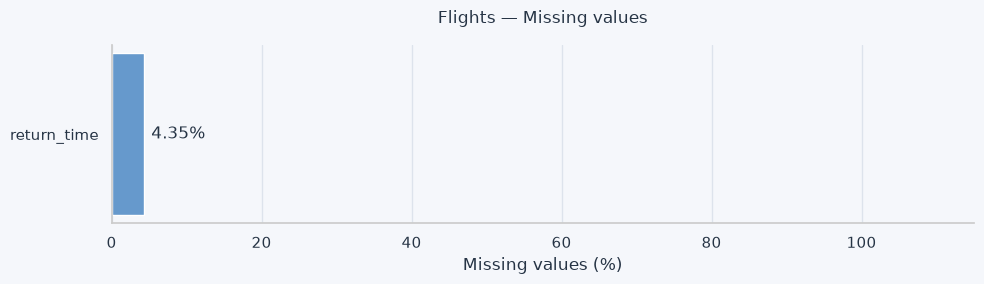

trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd
101486-1015905607d74b15954bfd4ac7029ef3,TCM,edmonton,YED,1,True,2023-06-10 10:00:00,2023-06-14 10:00:00,0,United Airlines,53.667000,-113.467000,189.910000
101961-19f641633ebc442799662326f0b4dfa0,BOS,new york,LGA,1,True,2023-05-05 11:00:00,2023-05-09 11:00:00,0,Allegiant Air,40.640000,-73.779000,49.670000
101961-29a8ff7c9910469c959fffa60215cf78,BOS,montreal,YHU,1,True,2023-02-08 07:00:00,2023-02-13 07:00:00,1,United Airlines,45.517000,-73.417000,77.020000
101961-836fd88487d240baa4402c8e4c6f188c,BOS,seattle,BFI,1,True,2023-03-16 07:00:00,2023-03-21 07:00:00,1,Kenmore Air,47.530000,-122.302000,769.500000
101961-c4c922fbc83342779565d249ee5e6bf7,BOS,charlotte,CLT,1,True,2023-06-27 11:00:00,2023-07-05 11:00:00,0,JetBlue Airways,35.214000,-80.943000,216.570000


trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd
801660-ac58e7357f4c4ea89215d21aa257946b,YKZ,chicago,UGN,1,True,2023-07-23 08:00:00,2023-07-26 08:00:00,0,United Airlines,41.786000,-87.752000,146.130000
801660-d7da52bc87254b69a3723fd71b8641eb,YKZ,chicago,ORD,1,True,2023-07-06 10:00:00,2023-07-09 10:00:00,1,WestJet,41.786000,-87.752000,122.800000
811077-f7b380273eba443aa97c90566b799733,TYS,fresno,FAT,1,True,2023-07-20 10:00:00,2023-07-28 10:00:00,0,Frontier Airlines,36.776000,-119.718000,579.790000
94883-6df625fce4364de499e99b0e608322e7,MCI,toronto,YZD,1,True,2023-03-27 07:00:00,2023-03-29 07:00:00,1,United Airlines,43.862000,-79.370000,240.920000
94883-bcc118ad37024c4ab14c62d46daf2ac0,MCI,jacksonville,LRF,2,True,2023-04-16 10:00:00,2023-04-17 10:00:00,0,Delta Air Lines,30.494000,-81.688000,623.170000


In [61]:
# inspect the original flight data without modifying it
flight_raw_profile = raw_data_overview(
    flights,
    name="Flights",
    key="trip_id",
)